# 13 · Focal-leaf test report (`powdery-mildew-ds2-focal-test`)

Scores the app's model (`runs/yolo26x-seg_data-v2/weights/best.pt`) on the **50 new hydrangea photos** from the second
round, labelled **focal leaf only**: one leaf per photo, with all its leaf spots and powdery mildew, hand-corrected.

**Unlabelled leaves are in the photos but must not count as mistakes.** So the model always sees what the app sees, and
we change *where we score*, not what the model sees:

| Mode | What the model sees | Scored where |
|---|---|---|
| **app** (main result) | full photo, shape kept, long side 1280 px, model input 1024 (the exported ONNX size; exactly like the backend) | only inside the labelled focal leaf (2-px edge, no margin) |
| **train-style** | full photo **stretched** to 1024×1024, imgsz 1024 (how the training data was exported) | same region |
| **isolated leaf** | photo with everything outside the focal leaf greyed out | same region |

Results per mode:
- **Pixel:** precision, recall, F1 and IoU per class, inside the focal leaf.
- **Coverage % of the focal leaf** (what the user sees): MAE, bias, CCC, severity-band accuracy and presence F1. This is
  computed two ways:
  - *given the labelled leaf*, which measures disease segmentation only;
  - *the app rule*, where the largest predicted leaf is the primary leaf, which also tests whether the app picks the
    right leaf.
- **Instance:** mask AP50 / AP50-95 per class (COCO). Only predictions that lie on the focal leaf are counted.
- **Ultralytics `val`:** run on the *isolated-leaf* photos, giving the standard table, PR curves and confusion matrix.
  It is also run once on the raw photos, to show how much unlabelled leaves would wrongly lower the score.

95 % CIs come from a bootstrap over photos. Everything is computed at the app's resolution (long side 1280).

In [1]:
import collections
import csv
import json
import os
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from dotenv import load_dotenv
from IPython.display import Image as IPImage, display
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from PIL import Image, ImageOps
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

from eval_utils import (CLASSES, DISEASES, confusion, coverage_primary_leaf, ensure_dataset, fill_holes,
                        iou_from_confusion, lins_ccc, paint_class_map, severity)

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")  # ROBOFLOW_API_KEY lives here (gitignored); never paste the key into a notebook
PROJECT, VERSION = "powdery-mildew-ds2-focal-test-23n1f", 1
CHECKPOINT = ROOT / "runs" / "yolo26x-seg_data-v2" / "weights" / "best.pt"
THRESH = {"leaf": 0.20, "leaf_spot": 0.25, "powdery_mildew": 0.30}  # backend/app/config.py (tuned on validation)
APP_SIDE = 1280  # backend: photo long side capped at 1280 (routes/scans.py load_image)
APP_IMGSZ = 1024  # model input the app runs at: the exported ONNX size, same as training
TRAIN_SIZE = 1024  # lds_v1-v2 export: Resize -> Stretch to 1024x1024
REGION_MARGIN = 0.0  # 0 = grey out everything except the labelled focal leaf (2-px edge only, so no neighbouring-leaf strips)
GREY = (114, 114, 114)  # Ultralytics' letterbox grey
N_BOOT, SEED = 1000, 0
MODES = ("app", "train-style", "isolated")
OUT = ROOT / "results" / f"focal_test_{PROJECT}-v{VERSION}"
OUT.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, fixed order (as in 08_test_report)
CLASS_COLOR = {"leaf": SERIES[0], "leaf_spot": SERIES[1], "powdery_mildew": SERIES[2]}
MODE_COLOR = dict(zip(MODES, SERIES))
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "savefig.dpi": 150, "savefig.bbox": "tight",
})
MAP_COLORS = ListedColormap(["#f0efec", "#b7d3f6", CLASS_COLOR["leaf_spot"], CLASS_COLOR["powdery_mildew"]])
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
print("checkpoint:", CHECKPOINT.relative_to(ROOT), "| results ->", OUT.relative_to(ROOT))

C:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


checkpoint: runs\yolo26x-seg_data-v2\weights\best.pt | results -> results\focal_test_powdery-mildew-ds2-focal-test-23n1f-v1


## Data

In [2]:
coco_dir, yolo_yaml = ensure_dataset(ROOT, PROJECT, VERSION, os.environ["ROBOFLOW_API_KEY"], os.environ["ROBOFLOW_WORKSPACE"])
gt = COCO(str(coco_dir / "test" / "_annotations.coco.json"))
CAT = {c["id"]: c["name"] for c in gt.loadCats(gt.getCatIds())}
CAT_ID = {n: i for i, n in CAT.items() if n in CLASSES}
images = sorted(gt.loadImgs(gt.getImgIds()), key=lambda im: im["file_name"])

counts = collections.Counter(CAT[a["category_id"]] for a in gt.loadAnns(gt.getAnnIds()))
leaves_per_img = collections.Counter(a["image_id"] for a in gt.loadAnns(gt.getAnnIds(catIds=[CAT_ID["leaf"]])))
NO_LEAF = [im["file_name"] for im in images if leaves_per_img[im["id"]] == 0]
MULTI_LEAF = [im["file_name"] for im in images if leaves_per_img[im["id"]] > 1]
print(f"{len(images)} photos | sizes {dict(collections.Counter((im['width'], im['height']) for im in images))}")
print("instances:", {c: counts[c] for c in CLASSES[1:]})
print("photos with no leaf label (left out of the scores):", NO_LEAF or "none")
print("photos with >1 leaf label (treated as one focal leaf):", MULTI_LEAF or "none")

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
50 photos | sizes {(3024, 4032): 49, (4032, 3024): 1}
instances: {'leaf': 50, 'leaf_spot': 809, 'powdery_mildew': 963}
photos with no leaf label (left out of the scores): ['20261001_183427153_iOS_jpg.rf.fd88830868387d65928d8fb6db40ac3e.jpg']
photos with >1 leaf label (treated as one focal leaf): ['20261001_203113347_iOS_jpg.rf.5cf2482e2ffc459e47e11ab4a613a894.jpg']


leaf_spot       present on 49/49 leaves | median 0.42 % | max 3.1 % | severity bands {'mild': 49}
powdery_mildew  present on 49/49 leaves | median 1.71 % | max 9.5 % | severity bands {'moderate': 7, 'mild': 42}


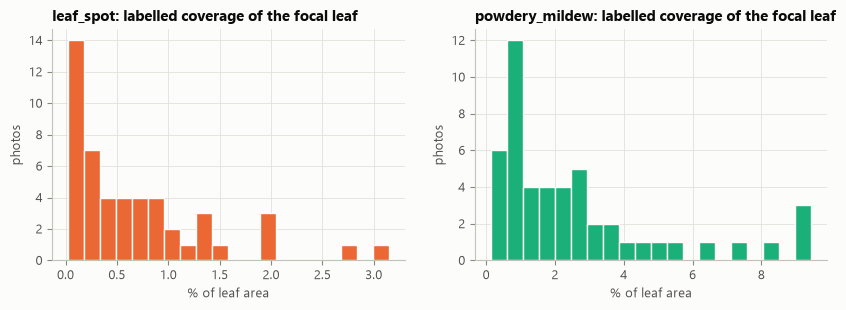

In [3]:
def app_image(path):
    # Same as backend/app/routes/scans.py load_image: EXIF orientation, long side capped at 1280.
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    im.thumbnail((APP_SIDE, APP_SIDE), Image.Resampling.LANCZOS)
    return im


def gt_at(img, size):
    # Labelled masks rasterised directly at the working size (polygons scaled, no full-res masks in memory).
    w, h = size
    sx, sy = w / img["width"], h / img["height"]
    out = {c: [] for c in CLASSES[1:]}
    for a in gt.loadAnns(gt.getAnnIds(imgIds=img["id"])):
        name = CAT[a["category_id"]]
        if name not in out:
            continue
        polys = [[v * (sx if k % 2 == 0 else sy) for k, v in enumerate(p)] for p in a["segmentation"] if len(p) >= 6]
        if polys:
            out[name].append(mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))).astype(bool))
    return out


def focal_leaf(g):
    # Focal leaf = all leaf shapes + the lesions on them, holes filled (lesions count as leaf area, as in the app).
    if not g["leaf"]:
        return None
    return fill_holes(np.logical_or.reduce(g["leaf"] + g["leaf_spot"] + g["powdery_mildew"]))


def dilate(mask, px):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * px + 1, 2 * px + 1))
    return cv2.dilate(mask.astype(np.uint8), k).astype(bool)


def sev(pct):
    return "none" if pct <= 0 else severity(pct)  # backend: 0 % -> "none"


# Ground-truth coverage of the focal leaf (what a perfect model would report).
gt_cov = {}
for img in images:
    im = app_image(coco_dir / "test" / img["file_name"])
    g = gt_at(img, im.size)
    leaf = focal_leaf(g)
    if leaf is not None:
        gt_cov[img["file_name"]] = {d: 100 * (np.logical_or.reduce(g[d] or [np.zeros_like(leaf)]) & leaf).sum() / leaf.sum()
                                    for d in DISEASES}
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, d in zip(axes, DISEASES):
    v = [c[d] for c in gt_cov.values()]
    ax.hist(v, bins=20, color=CLASS_COLOR[d], edgecolor=SURFACE)
    ax.set_title(f"{d}: labelled coverage of the focal leaf")
    ax.set_xlabel("% of leaf area"); ax.set_ylabel("photos")
    print(f"{d:<15} present on {sum(x > 0 for x in v)}/{len(v)} leaves | median {np.median(v):.2f} % | max {max(v):.1f} % | "
          f"severity bands {dict(collections.Counter(sev(x) for x in v))}")
plt.show()

## Run the model (three modes)

- **Predictions:** kept at the tuned per-class thresholds, as in the backend.
- **Scoring region:** each photo is scored only inside its labelled focal leaf (2-px edge, no margin), so neighbouring leaves are greyed out / ignored.
- **Instance level:** a predicted instance counts if at least half of it lies in that region. Predictions on other
  leaves are ignored.

In [4]:
model = YOLO(CHECKPOINT)


def predict(im, imgsz, out_size):
    r = model.predict(im, imgsz=imgsz, conf=min(THRESH.values()), iou=0.7, retina_masks=True, max_det=300, verbose=False)[0]
    if r.masks is None:
        return []
    preds = []
    for m, c, s in zip(r.masks.data.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
        name = r.names[int(c)]
        if s >= THRESH[name]:
            m = m.astype(bool)
            if m.shape[::-1] != out_size:  # train-style: back from the stretched square to the photo's shape
                m = cv2.resize(m.astype(np.uint8), out_size, interpolation=cv2.INTER_NEAREST).astype(bool)
            if m.any():
                preds.append((name, float(s), m))
    return preds


rows, conf_mats, dets, keep_maps = [], {m: {} for m in MODES}, {m: [] for m in MODES}, {}
gt_small = {"images": [], "annotations": [], "categories": [{"id": i, "name": n} for n, i in CAT_ID.items()]}
for k, img in enumerate(images, 1):
    name = img["file_name"]
    im = app_image(coco_dir / "test" / name)
    g = gt_at(img, im.size)
    leaf = focal_leaf(g)
    if leaf is None:
        continue
    h, w = leaf.shape
    region = dilate(leaf, max(2, int(REGION_MARGIN * max(h, w))))
    gt_map = paint_class_map(sum(g.values(), []), sum(([c] * len(g[c]) for c in g), []), (h, w))
    gt_small["images"].append({"id": img["id"], "file_name": name, "width": w, "height": h})
    for c, masks in g.items():
        for m in masks:
            rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
            rle["counts"] = rle["counts"].decode()
            gt_small["annotations"].append({"id": len(gt_small["annotations"]) + 1, "image_id": img["id"],
                                            "category_id": CAT_ID[c], "segmentation": rle, "iscrowd": 0,
                                            "area": float(m.sum()), "bbox": list(mask_utils.toBbox(rle))})
    inputs = {
        "app": (im, APP_IMGSZ),
        "train-style": (im.resize((TRAIN_SIZE, TRAIN_SIZE), Image.Resampling.BILINEAR), TRAIN_SIZE),
        "isolated": (Image.fromarray(np.where(region[..., None], np.asarray(im), np.array(GREY, np.uint8))), APP_IMGSZ),
    }
    for mode, (x, imgsz) in inputs.items():
        preds = predict(x, imgsz, (w, h))
        names = [p[0] for p in preds]
        masks = [p[2] for p in preds]
        pred_map = paint_class_map(masks, names, (h, w))
        conf_mats[mode][name] = confusion(gt_map[region], pred_map[region])
        if mode == "app":
            keep_maps[name] = (pred_map, region)
        # Coverage given the labelled leaf: predicted disease pixels inside it / its area.
        cov_region = {d: 100 * ((pred_map == CLASSES.index(d)) & leaf).sum() / leaf.sum() for d in DISEASES}
        # App rule: largest predicted leaf = primary, coverage computed exactly as the backend does.
        cov_app = coverage_primary_leaf(masks, names) or {d: 0.0 for d in DISEASES}
        pred_leaves = sorted((fill_holes(m) for n, _, m in preds if n == "leaf"), key=lambda m: -int(m.sum()))
        primary_iou = float((pred_leaves[0] & leaf).sum() / (pred_leaves[0] | leaf).sum()) if pred_leaves else 0.0
        rows.append({"file": name, "mode": mode, "primary_iou": primary_iou, "n_pred_leaves": len(pred_leaves),
                     **{f"gt_{d}": gt_cov[name][d] for d in DISEASES},
                     **{f"region_{d}": cov_region[d] for d in DISEASES},
                     **{f"app_{d}": cov_app[d] for d in DISEASES}})
        for n, s, m in preds:
            if (m & region).sum() >= 0.5 * m.sum():
                rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
                rle["counts"] = rle["counts"].decode()
                dets[mode].append({"image_id": img["id"], "category_id": CAT_ID[n], "segmentation": rle, "score": s})
    if k % 10 == 0 or k == len(images):
        print(f"{k}/{len(images)} photos", flush=True)
FILES = sorted(conf_mats["app"])
print(f"scored {len(FILES)} photos")

10/50 photos


20/50 photos


30/50 photos


40/50 photos


50/50 photos


scored 49 photos


## Metrics with 95 % bootstrap CIs

In [5]:
rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, len(FILES), len(FILES)) for _ in range(N_BOOT)]
by_mode = {m: {r["file"]: r for r in rows if r["mode"] == m} for m in MODES}


def pixel_scores(mats):
    c = sum(mats)
    tp = np.diag(c).astype(float)
    p, r = tp / np.maximum(c.sum(0), 1), tp / np.maximum(c.sum(1), 1)
    iou = iou_from_confusion(c)
    return {cls: {"precision": p[i], "recall": r[i], "f1": 2 * p[i] * r[i] / max(p[i] + r[i], 1e-9), "iou": iou[cls]}
            for i, cls in enumerate(CLASSES) if cls != "background"}


def coverage_scores(rs, key):
    out = {}
    for d in DISEASES:
        g = np.array([r[f"gt_{d}"] for r in rs]); p = np.array([r[f"{key}_{d}"] for r in rs])
        pos = g > 0
        tp, fp, fn = int(((p > 0) & pos).sum()), int(((p > 0) & ~pos).sum()), int(((p == 0) & pos).sum())
        out[d] = {"mae": float(np.abs(p - g).mean()), "mae_infected": float(np.abs(p - g)[pos].mean()) if pos.any() else np.nan,
                  "bias": float((p - g).mean()), "ccc": lins_ccc(g, p),
                  "severity_acc": float(np.mean([sev(a) == sev(b) for a, b in zip(g, p)])),
                  "presence_f1": 2 * tp / max(2 * tp + fp + fn, 1)}
    return out


def flat(d, prefix=""):
    out = {}
    for k, v in d.items():
        out.update(flat(v, f"{prefix}{k}.") if isinstance(v, dict) else {f"{prefix}{k}": v})
    return out


def scores(mode, idx):
    files = [FILES[i] for i in idx]
    rs = [by_mode[mode][f] for f in files]
    return flat({"pixel": pixel_scores([conf_mats[mode][f] for f in files]),
                 "coverage_given_leaf": coverage_scores(rs, "region"),
                 "coverage_app_rule": coverage_scores(rs, "app"),
                 "primary_leaf_correct": float(np.mean([r["primary_iou"] >= 0.5 for r in rs]))})


RESULTS = {}
for mode in MODES:
    point = scores(mode, np.arange(len(FILES)))
    boots = [scores(mode, b) for b in BOOT]
    RESULTS[mode] = {k: {"value": v, "ci95": [float(np.nanpercentile([b[k] for b in boots], 2.5)),
                                               float(np.nanpercentile([b[k] for b in boots], 97.5))]}
                     for k, v in point.items()}
print("bootstrap done")

bootstrap done


In [6]:
def fmt(mode, key, pct=False, digits=2):
    v = RESULTS[mode][key]
    f = (lambda x: f"{100 * x:.0f}%") if pct else (lambda x: f"{x:.{digits}f}")
    return f"{f(v['value'])} [{f(v['ci95'][0])}–{f(v['ci95'][1])}]"


table = [("Pixel IoU · leaf", "pixel.leaf.iou", False), ("Pixel IoU · leaf spot", "pixel.leaf_spot.iou", False),
         ("Pixel IoU · mildew", "pixel.powdery_mildew.iou", False),
         ("Pixel F1 · leaf spot", "pixel.leaf_spot.f1", False), ("Pixel F1 · mildew", "pixel.powdery_mildew.f1", False),
         ("Spot coverage MAE (pp)", "coverage_given_leaf.leaf_spot.mae", False),
         ("Mildew coverage MAE (pp)", "coverage_given_leaf.powdery_mildew.mae", False),
         ("Spot coverage bias (pp)", "coverage_given_leaf.leaf_spot.bias", False),
         ("Mildew coverage bias (pp)", "coverage_given_leaf.powdery_mildew.bias", False),
         ("Spot CCC", "coverage_given_leaf.leaf_spot.ccc", False), ("Mildew CCC", "coverage_given_leaf.powdery_mildew.ccc", False),
         ("Spot severity band correct", "coverage_given_leaf.leaf_spot.severity_acc", True),
         ("Mildew severity band correct", "coverage_given_leaf.powdery_mildew.severity_acc", True),
         ("App: mildew MAE (pp)", "coverage_app_rule.powdery_mildew.mae", False),
         ("App: spot MAE (pp)", "coverage_app_rule.leaf_spot.mae", False),
         ("App picks the focal leaf", "primary_leaf_correct", True)]
print(f"{'metric':<30}" + "".join(f"{m:>26}" for m in MODES))
for label, key, pct in table:
    print(f"{label:<30}" + "".join(f"{fmt(m, key, pct):>26}" for m in MODES))
print("\npp = percentage points of leaf area. 'given leaf' = coverage inside the labelled leaf; 'App' = backend rule "
      "(largest predicted leaf). [95 % CI]")

metric                                               app               train-style                  isolated
Pixel IoU · leaf                        0.97 [0.97–0.98]          0.96 [0.96–0.97]          0.98 [0.97–0.98]
Pixel IoU · leaf spot                   0.71 [0.65–0.76]          0.68 [0.60–0.75]          0.69 [0.63–0.74]
Pixel IoU · mildew                      0.72 [0.66–0.76]          0.70 [0.64–0.74]          0.71 [0.66–0.75]
Pixel F1 · leaf spot                    0.83 [0.79–0.86]          0.81 [0.75–0.85]          0.82 [0.78–0.85]
Pixel F1 · mildew                       0.84 [0.80–0.86]          0.82 [0.78–0.85]          0.83 [0.79–0.86]
Spot coverage MAE (pp)                  0.14 [0.10–0.19]          0.15 [0.09–0.23]          0.16 [0.11–0.20]
Mildew coverage MAE (pp)                0.25 [0.15–0.38]          0.32 [0.20–0.49]          0.31 [0.21–0.44]
Spot coverage bias (pp)                 0.10 [0.05–0.15]         0.03 [-0.06–0.10]          0.14 [0.09–0.18]
Mildew coverage bia

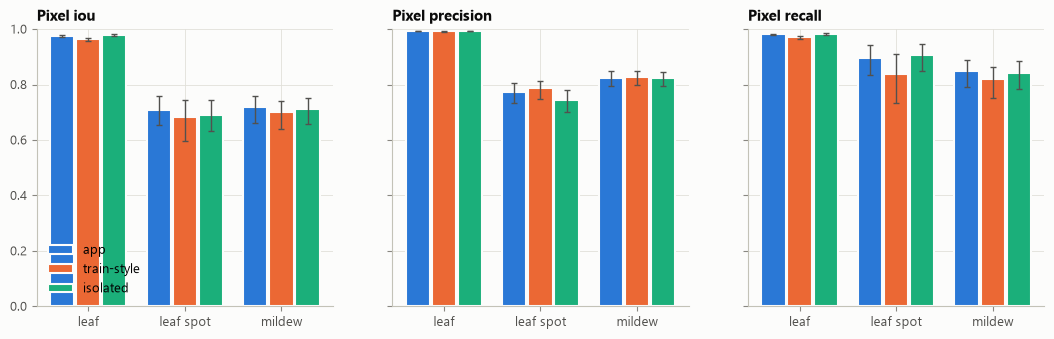

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, metric in zip(axes, ("iou", "precision", "recall")):
    x = np.arange(3)
    for j, mode in enumerate(MODES):
        vals = [RESULTS[mode][f"pixel.{c}.{metric}"] for c in ("leaf", "leaf_spot", "powdery_mildew")]
        y = np.array([v["value"] for v in vals]); lo = y - [v["ci95"][0] for v in vals]; hi = [v["ci95"][1] for v in vals] - y
        ax.bar(x + (j - 1) * 0.27, y, 0.25, yerr=[lo, hi], color=MODE_COLOR[mode], edgecolor=SURFACE, linewidth=1.5,
               error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2}, label=mode)
    ax.set_xticks(x, ["leaf", "leaf spot", "mildew"]); ax.set_ylim(0, 1); ax.set_title(f"Pixel {metric}")
axes[0].legend(loc="lower left")
fig.savefig(OUT / "pixel_metrics.png"); plt.show()

### Pixel confusion inside the focal leaf (app mode, rows = label, normalised)

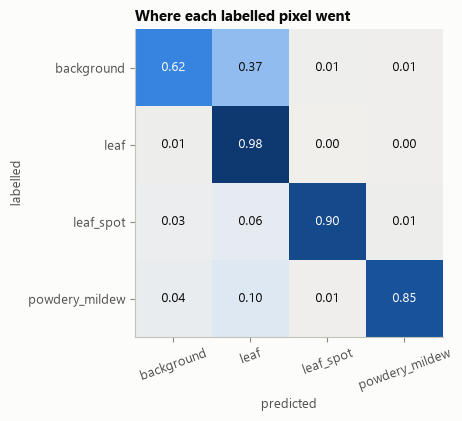

In [8]:
c = sum(conf_mats["app"][f] for f in FILES).astype(float)
c = c[1:, 1:] if c[0].sum() == 0 else c  # background is only the margin around the leaf; keep it if present
labels = CLASSES[1:] if c.shape[0] == 3 else CLASSES
cn = c / np.maximum(c.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cn, cmap=BLUES, vmin=0, vmax=1); ax.grid(False)
for i in range(cn.shape[0]):
    for j in range(cn.shape[1]):
        ax.text(j, i, f"{cn[i, j]:.2f}", ha="center", va="center", color="white" if cn[i, j] > 0.55 else INK, fontsize=9)
ax.set_xticks(range(len(labels)), labels, rotation=20); ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("predicted"); ax.set_ylabel("labelled"); ax.set_title("Where each labelled pixel went")
fig.savefig(OUT / "pixel_confusion_app.png"); plt.show()

### Coverage: labelled vs predicted (app mode, given the labelled leaf)

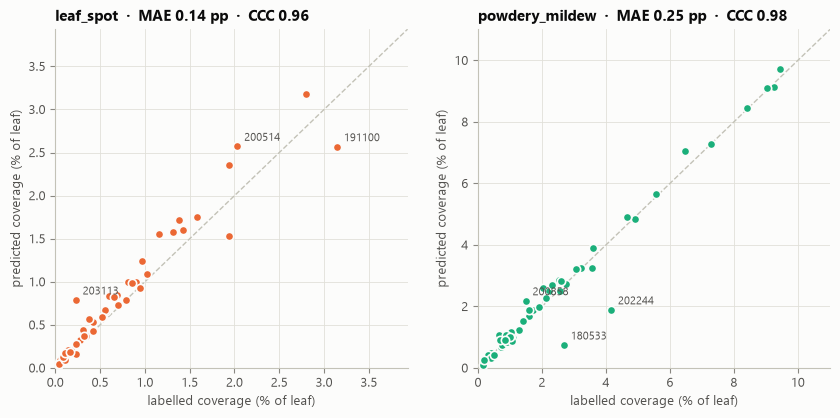

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, d in zip(axes, DISEASES):
    rs = list(by_mode["app"].values())
    g = np.array([r[f"gt_{d}"] for r in rs]); p = np.array([r[f"region_{d}"] for r in rs])
    top = max(g.max(), p.max()) * 1.08 + 0.5
    ax.plot([0, top], [0, top], color=AXIS, linewidth=1, linestyle="--", zorder=1)
    ax.scatter(g, p, s=36, color=CLASS_COLOR[d], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.set_xlim(0, top); ax.set_ylim(0, top)
    ax.set_xlabel("labelled coverage (% of leaf)"); ax.set_ylabel("predicted coverage (% of leaf)")
    r = RESULTS["app"]
    ax.set_title(f"{d}  ·  MAE {r[f'coverage_given_leaf.{d}.mae']['value']:.2f} pp  ·  "
                 f"CCC {r[f'coverage_given_leaf.{d}.ccc']['value']:.2f}")
    worst = np.argsort(-np.abs(p - g))[:3]
    for i in worst:
        ax.annotate(rs[i]["file"][9:15], (g[i], p[i]), textcoords="offset points", xytext=(5, 4), fontsize=8, color=INK2)
fig.savefig(OUT / "coverage_scatter.png"); plt.show()

### Instance level: mask AP (COCO), predictions on the focal leaf only

In [10]:
gt_coco = COCO(); gt_coco.dataset = gt_small; gt_coco.createIndex()
AP = {}
for mode in MODES:
    dt = gt_coco.loadRes(dets[mode]) if dets[mode] else None
    if dt is None:
        continue
    ev = COCOeval(gt_coco, dt, "segm"); ev.params.maxDets = [10, 100, 300]
    ev.evaluate(); ev.accumulate()
    prec = ev.eval["precision"]  # [IoU thr, recall, class, area, maxDets]
    AP[mode] = {}
    for k, cid in enumerate(ev.params.catIds):
        p = prec[:, :, k, 0, -1]
        valid = lambda a: float(a[a > -1].mean()) if (a > -1).any() else float("nan")  # noqa: E731
        AP[mode][next(n for n, i in CAT_ID.items() if i == cid)] = {"ap50": valid(p[0]), "ap50_95": valid(p)}
print(f"{'class':<16}" + "".join(f"{m + ' AP50':>18}{m + ' AP50-95':>20}" for m in AP))
for c in CLASSES[1:]:
    print(f"{c:<16}" + "".join(f"{AP[m][c]['ap50']:>18.3f}{AP[m][c]['ap50_95']:>20.3f}" for m in AP))

creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.21s).
Accumulating evaluation results...


DONE (t=0.02s).
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*


DONE (t=0.21s).
Accumulating evaluation results...
DONE (t=0.01s).
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*


DONE (t=0.22s).
Accumulating evaluation results...
DONE (t=0.01s).
class                     app AP50         app AP50-95  train-style AP50 train-style AP50-95     isolated AP50    isolated AP50-95
leaf                         0.969               0.896             0.980               0.881             0.980               0.937
leaf_spot                    0.796               0.435             0.783               0.358             0.829               0.465
powdery_mildew               0.692               0.462             0.651               0.423             0.674               0.461


## Ultralytics `val`

The isolated-leaf copies are written as a YOLO dataset: the labels are unchanged, and everything outside the focal leaf
is grey. This makes Ultralytics' own metrics and plots fair. For contrast, the same run on the **raw photos**: there,
every correct prediction on an unlabelled leaf counts as a false positive.

In [11]:
src = Path(yolo_yaml).parent / "test"
iso = OUT / "isolated_yolo"
shutil.rmtree(iso, ignore_errors=True)
(iso / "images").mkdir(parents=True); (iso / "labels").mkdir()
for img in gt_small["images"]:
    name = img["file_name"]
    im = app_image(coco_dir / "test" / name)
    region = dilate(focal_leaf(gt_at(gt.imgs[img["id"]], im.size)), max(2, int(REGION_MARGIN * max(im.size))))
    Image.fromarray(np.where(region[..., None], np.asarray(im), np.array(GREY, np.uint8))).save(iso / "images" / name, quality=95)
    shutil.copy(src / "labels" / (Path(name).stem + ".txt"), iso / "labels")
names = yaml.safe_load(open(yolo_yaml))["names"]
assert list(names) == list(YOLO(CHECKPOINT).names.values()), f"class order differs: {names}"
iso_yaml = OUT / "isolated.yaml"
yaml.safe_dump({"path": str(iso), "train": "images", "val": "images", "names": names}, open(iso_yaml, "w"))

val_iso = model.val(data=str(iso_yaml), imgsz=APP_IMGSZ, batch=4, conf=0.001, iou=0.7, workers=0, plots=True,
                    project=str(OUT), name="ultralytics_isolated", exist_ok=True, verbose=True)
raw_yaml = OUT / "raw.yaml"
yaml.safe_dump({"path": str(src.parent), "train": "test/images", "val": "test/images", "names": names}, open(raw_yaml, "w"))
val_raw = model.val(data=str(raw_yaml), imgsz=APP_IMGSZ, batch=4, conf=0.001, iou=0.7, workers=0, plots=False,
                    project=str(OUT), name="ultralytics_raw", exist_ok=True, verbose=False)
print(f"\nmask mAP50 · isolated leaf {val_iso.seg.map50:.3f} vs raw photos {val_raw.seg.map50:.3f} "
      f"(unlabelled leaves count as false positives in the raw run)")
for i, c in enumerate(val_iso.seg.ap_class_index):
    j = list(val_raw.seg.ap_class_index).index(c)
    print(f"  {names[c]:<15} isolated mAP50 {val_iso.seg.ap50[i]:.3f}  mAP50-95 {val_iso.seg.ap[i]:.3f}   |  raw mAP50 {val_raw.seg.ap50[j]:.3f}")

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)


YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 605.1±125.9 MB/s, size: 380.0 KB)


val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_test_powdery-mildew-ds2-focal-test-23n1f-v1\isolated_yolo\labels... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 1.3Kit/s 0.0s

val: New cache created: C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_test_powdery-mildew-ds2-focal-test-23n1f-v1\isolated_yolo\labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 7% ╸─────────── 1/13 1.1s/it 0.3s<12.6s

... (34 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.3it/s 3.0s

                   all         50       1822      0.471      0.838      0.524      0.373      0.429      0.735      0.428      0.224


Speed: 0.3ms preprocess, 14.5ms inference, 0.0ms loss, 1.8ms postprocess per image



mask mAP50 · isolated leaf 0.788 vs raw photos 0.428 (unlabelled leaves count as false positives in the raw run)
  leaf            isolated mAP50 0.975  mAP50-95 0.969   |  raw mAP50 0.124
  leaf_spot       isolated mAP50 0.652  mAP50-95 0.266   |  raw mAP50 0.499
  powdery_mildew  isolated mAP50 0.738  mAP50-95 0.417   |  raw mAP50 0.661


MaskPR_curve.png


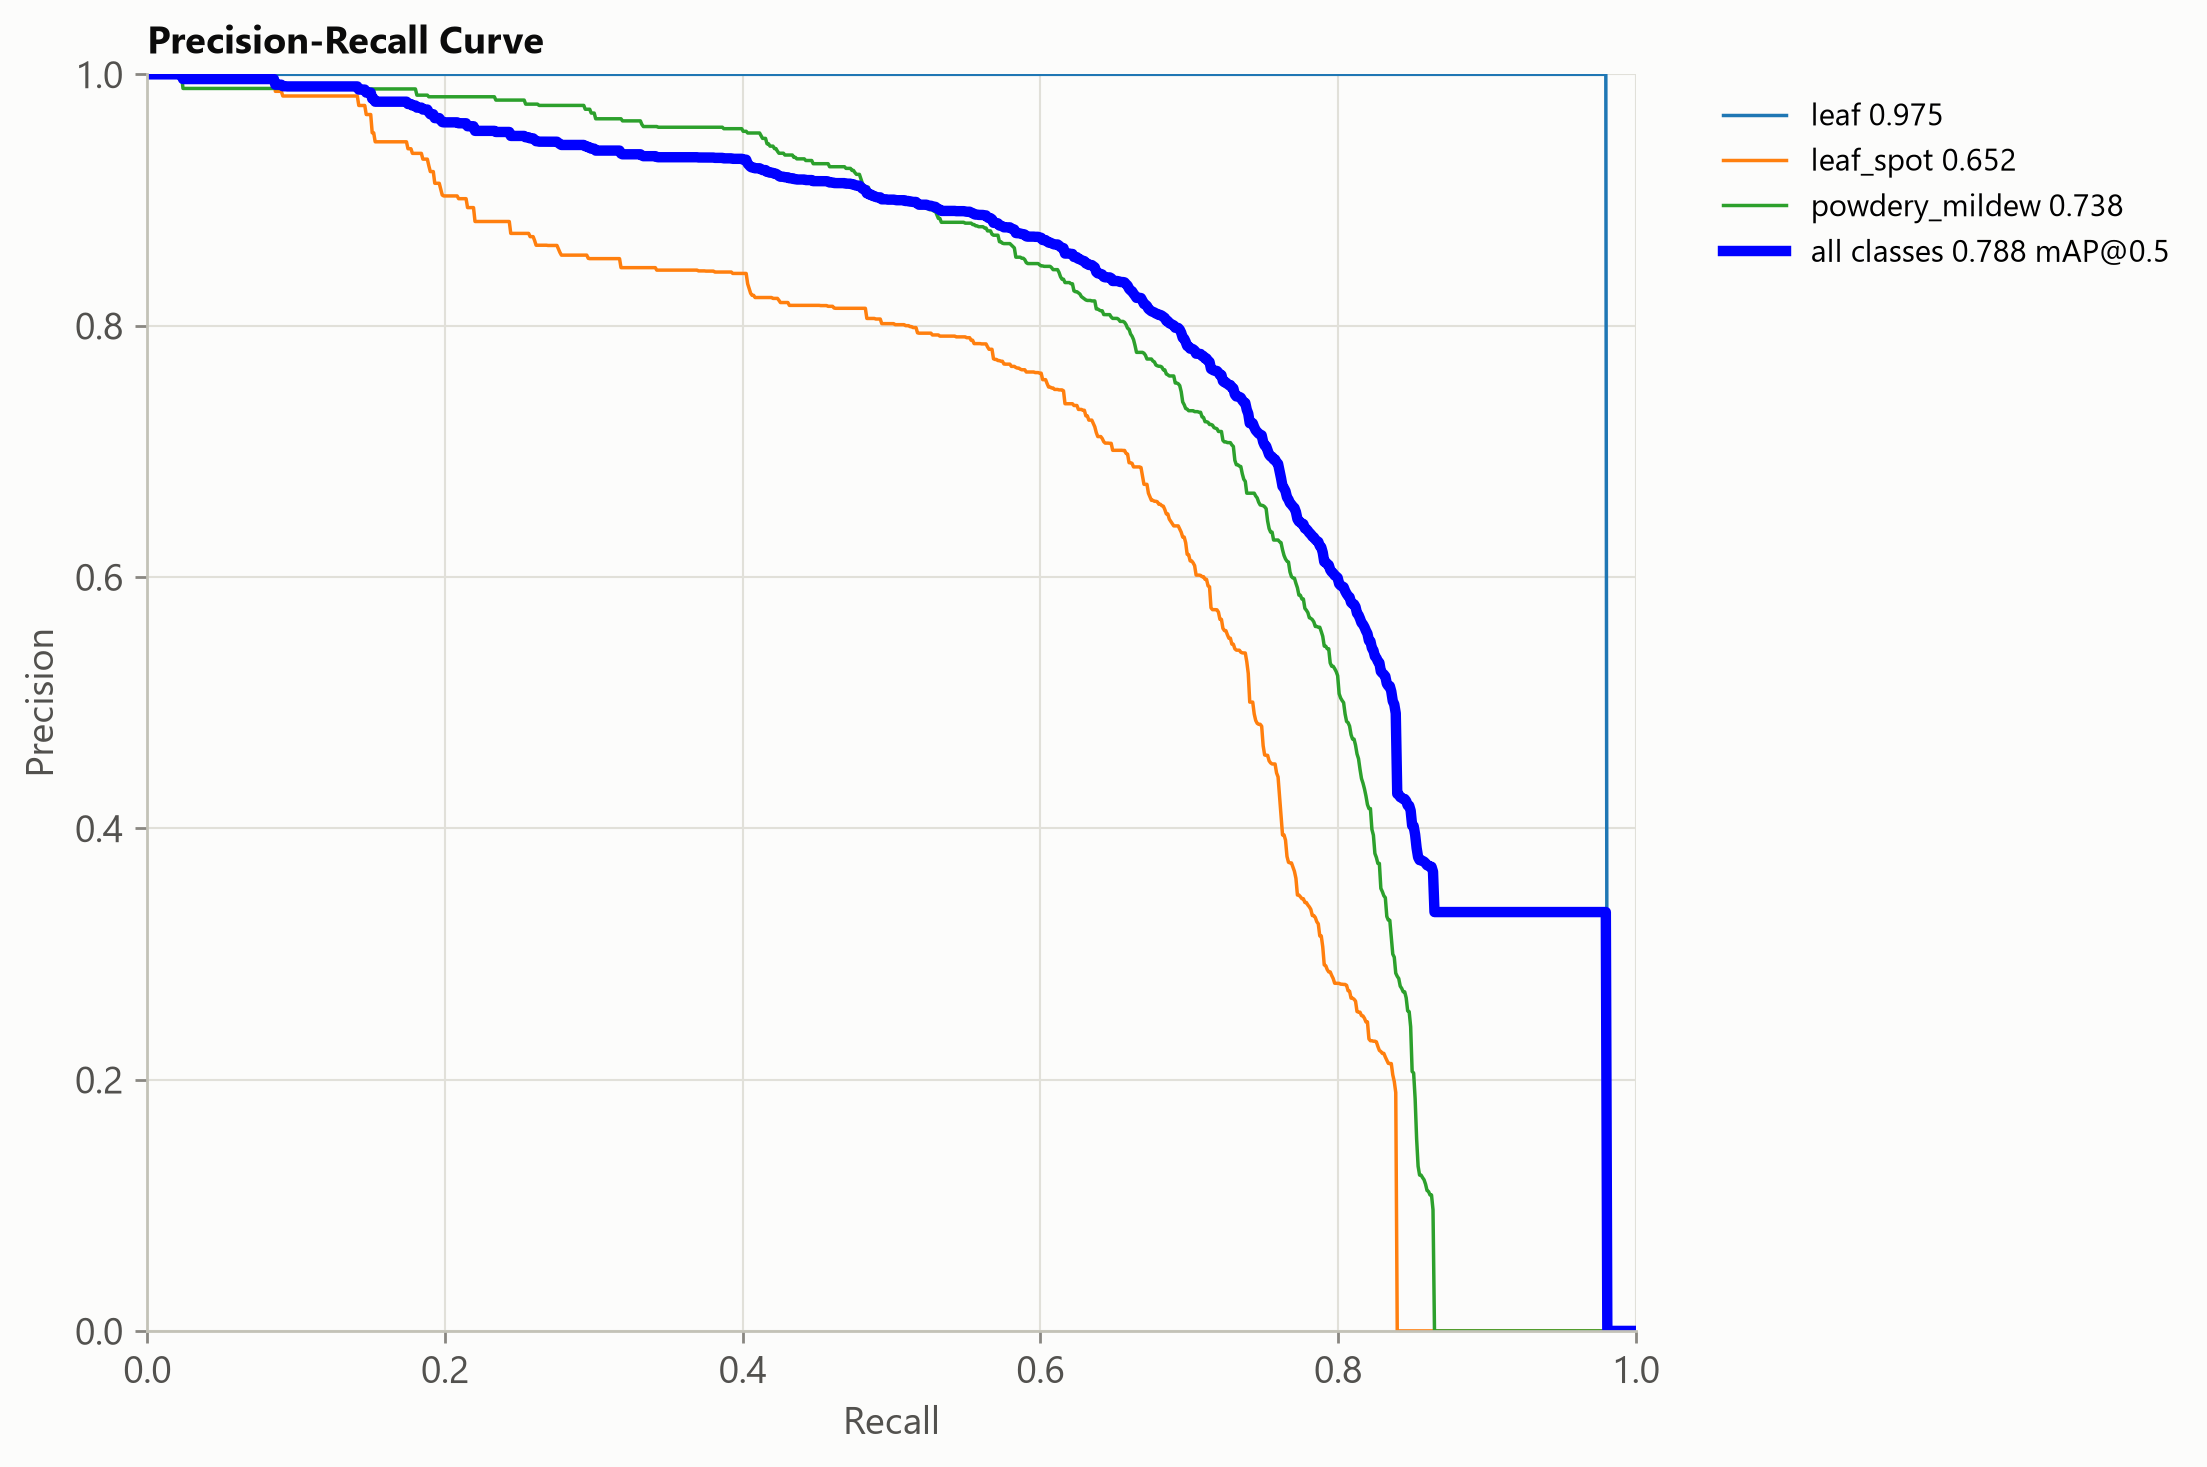

confusion_matrix_normalized.png


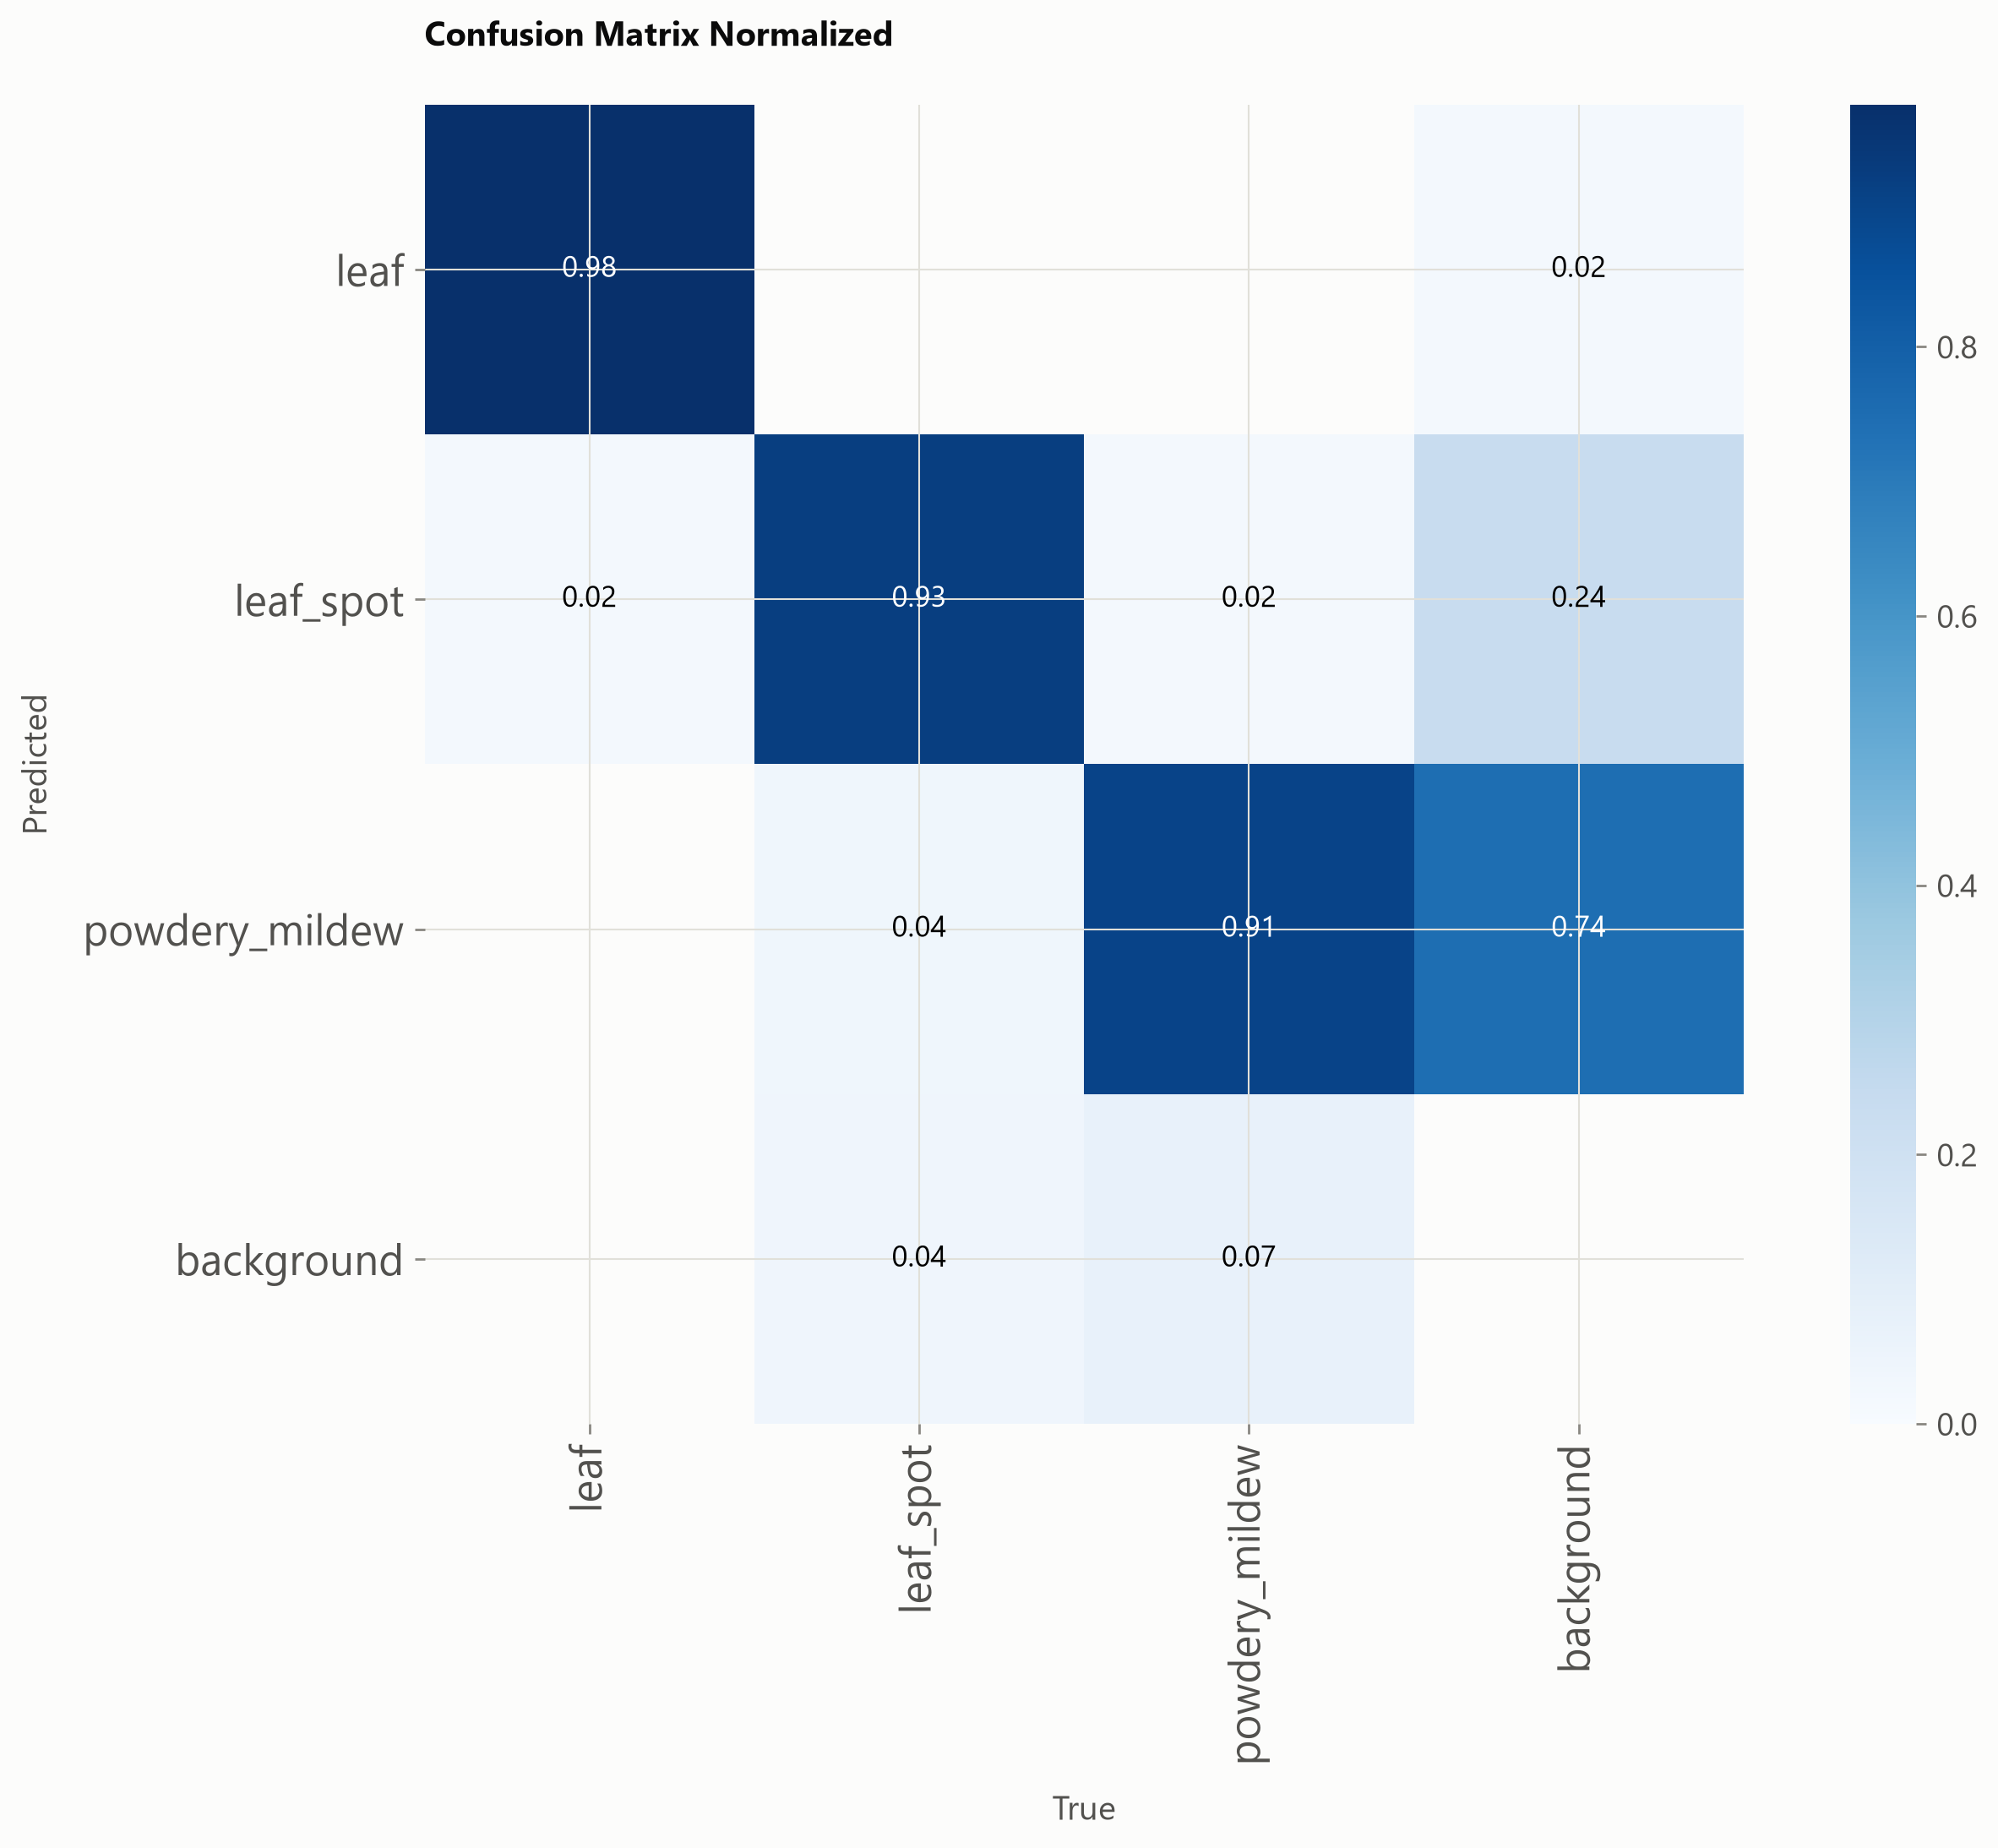

val_batch0_pred.jpg


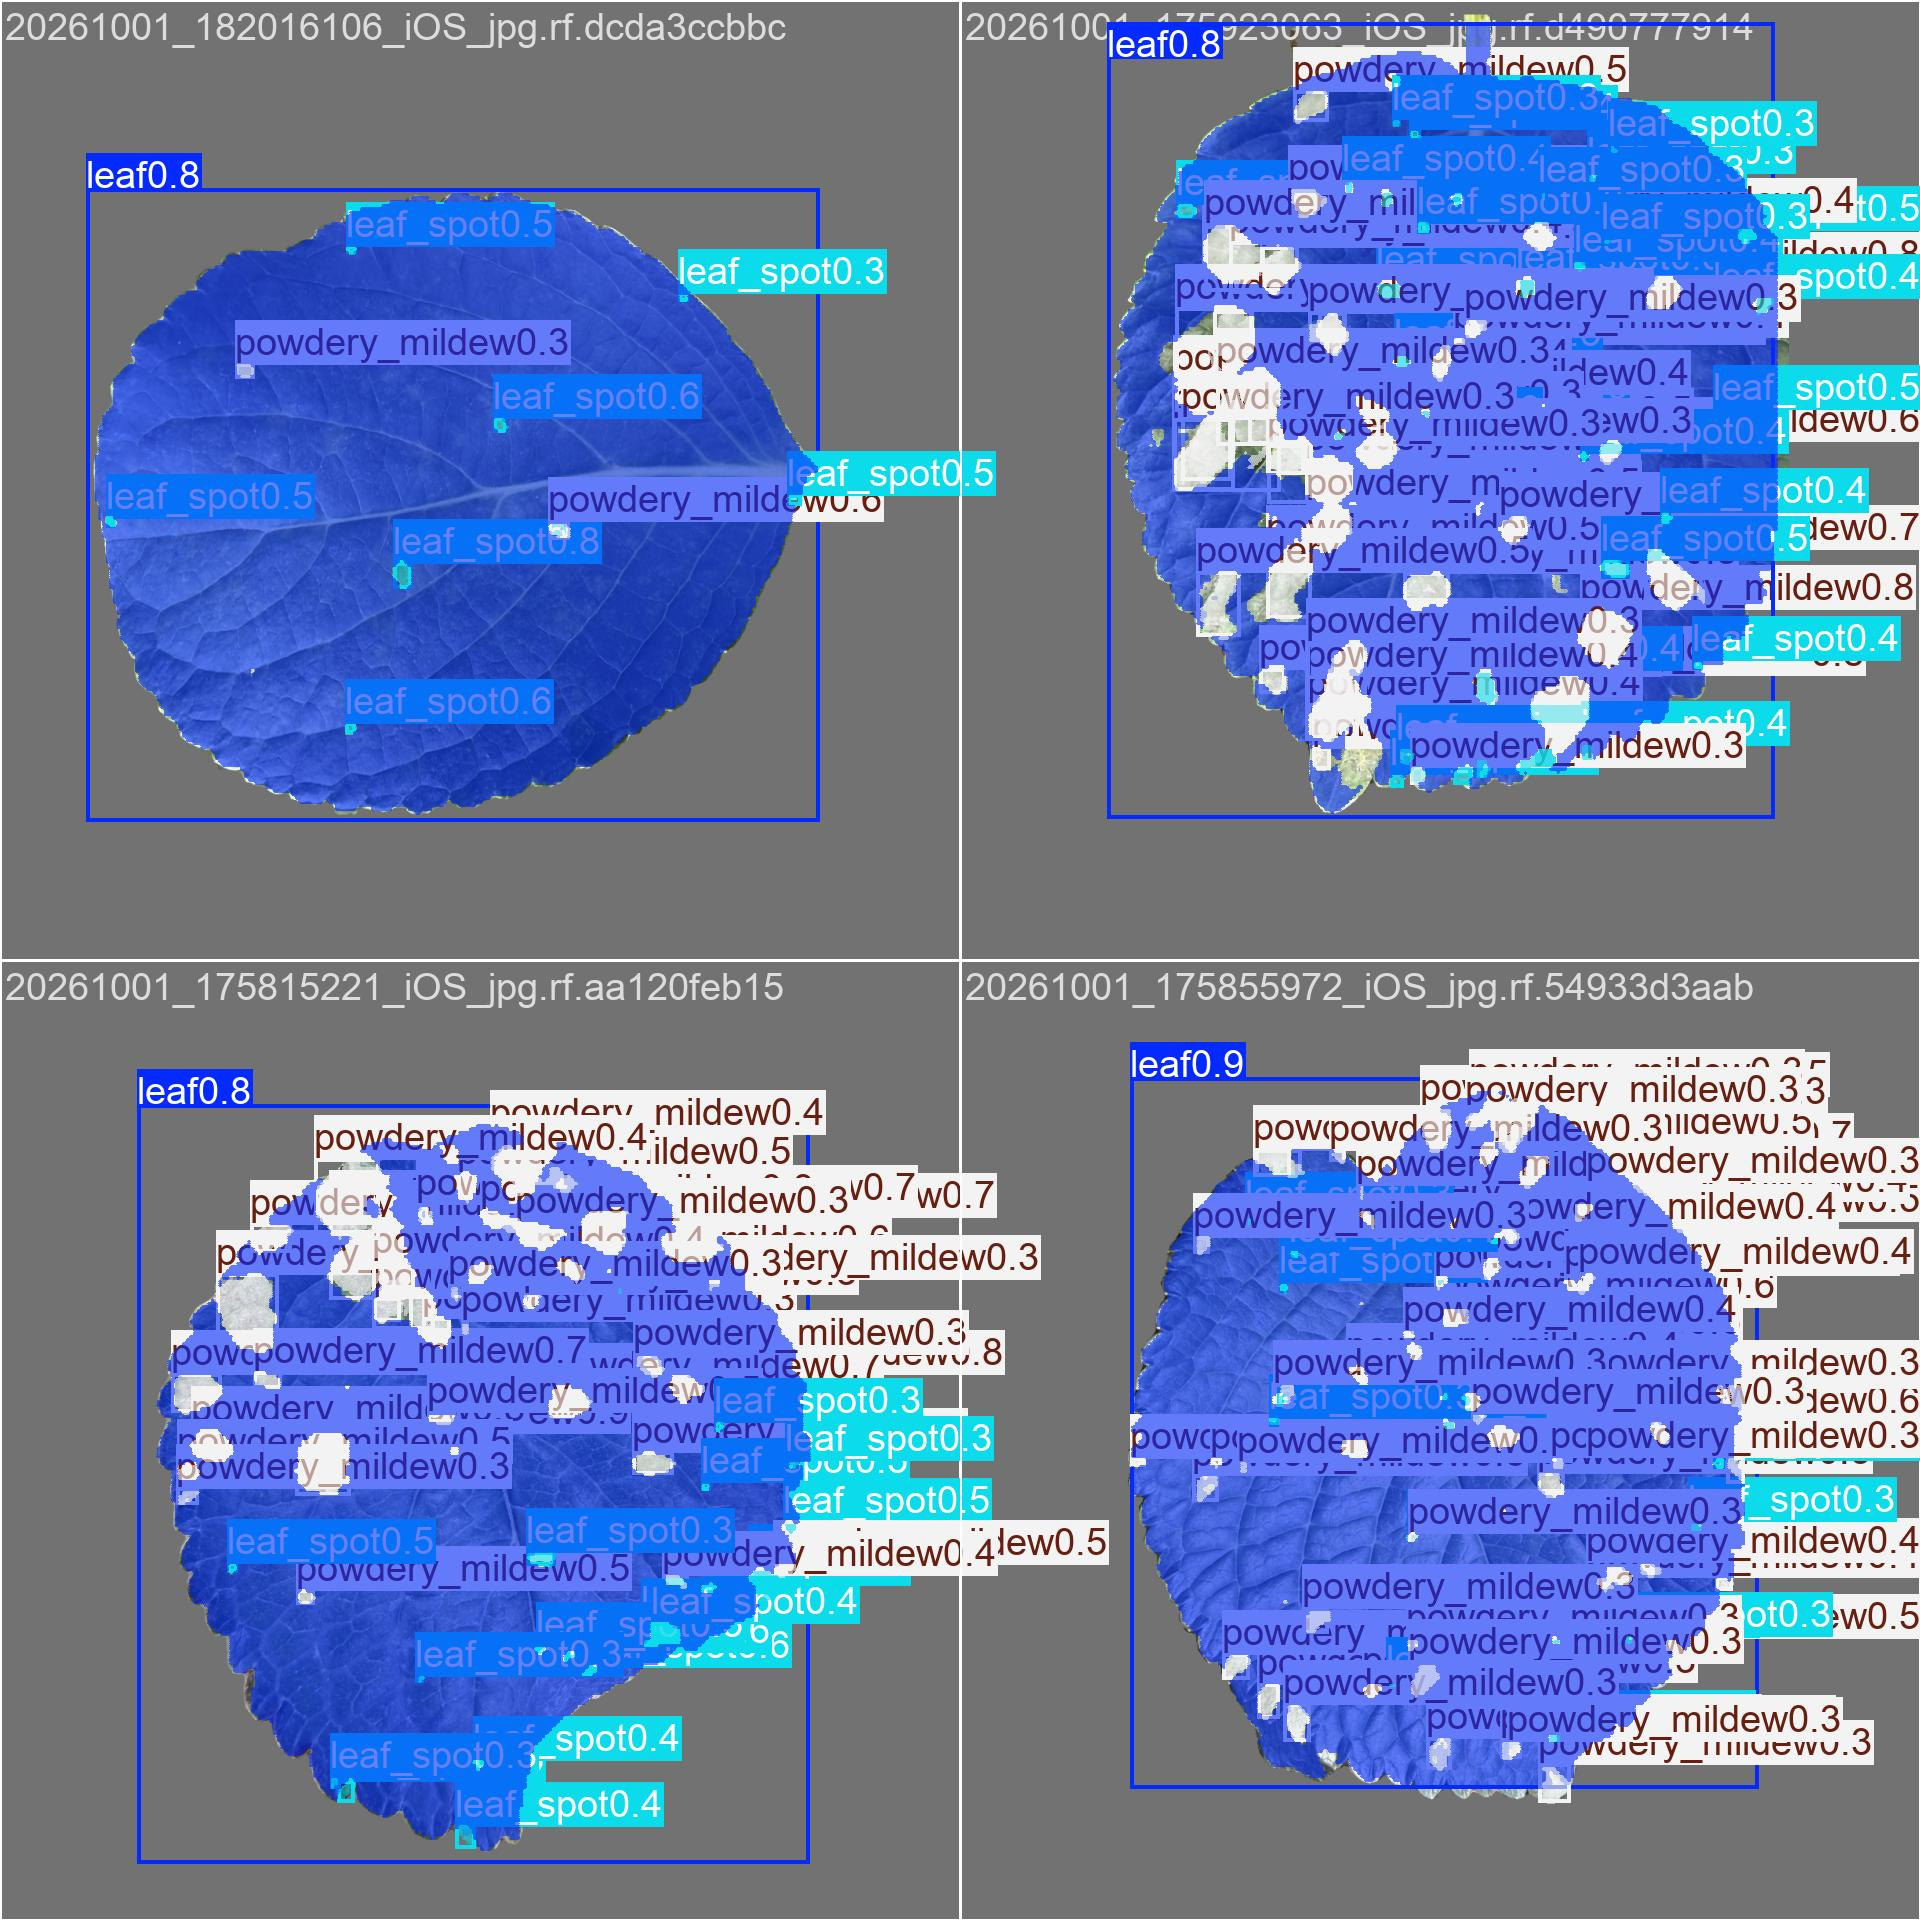

In [12]:
plots = OUT / "ultralytics_isolated"
for f in ("MaskPR_curve.png", "confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    p = plots / f
    if p.exists():
        print(f); display(IPImage(filename=str(p), width=760))

## Compared with the old test set (`lds_v1-v2` test, 76 photos, all leaves labelled)

In [13]:
old_path = ROOT / "results" / "final_metrics_lds_v1-v2_76.json"
old = json.load(open(old_path))["v2 tuned"] if old_path.exists() else None
rows_cmp = [("Pixel IoU · leaf", "pixel.leaf.iou", ("pixel", "leaf", "iou")),
            ("Pixel IoU · leaf spot", "pixel.leaf_spot.iou", ("pixel", "leaf_spot", "iou")),
            ("Pixel IoU · mildew", "pixel.powdery_mildew.iou", ("pixel", "powdery_mildew", "iou")),
            ("Spot presence F1", "coverage_given_leaf.leaf_spot.presence_f1", ("image", "leaf_spot", "presence_f1")),
            ("Mildew presence F1", "coverage_given_leaf.powdery_mildew.presence_f1", ("image", "powdery_mildew", "presence_f1")),
            ("Spot coverage MAE (pp)", "coverage_given_leaf.leaf_spot.mae", ("image", "leaf_spot", "mae")),
            ("Mildew coverage MAE (pp)", "coverage_given_leaf.powdery_mildew.mae", ("image", "powdery_mildew", "mae"))]
print(f"{'metric':<26}{'old test (lds, 76)':>20}{'new focal test (app mode)':>30}")
for label, new_key, (a, b, c) in rows_cmp:
    o = old[a][b][c] if old else float("nan")
    print(f"{label:<26}{o:>20.3f}{fmt('app', new_key):>30}")
print("\nNot a like-for-like comparison: different photos (new garden session), different labelling protocol "
      "(focal leaf only), and the old numbers are image-level over all leaves.")

metric                      old test (lds, 76)     new focal test (app mode)
Pixel IoU · leaf                         0.878              0.97 [0.97–0.98]
Pixel IoU · leaf spot                    0.666              0.71 [0.65–0.76]
Pixel IoU · mildew                       0.519              0.72 [0.66–0.76]
Spot presence F1                         0.971              1.00 [1.00–1.00]
Mildew presence F1                       1.000              1.00 [1.00–1.00]
Spot coverage MAE (pp)                   0.352              0.14 [0.10–0.19]
Mildew coverage MAE (pp)                 0.357              0.25 [0.15–0.38]

Not a like-for-like comparison: different photos (new garden session), different labelling protocol (focal leaf only), and the old numbers are image-level over all leaves.


## Pictures: where the model is right and wrong (app mode)

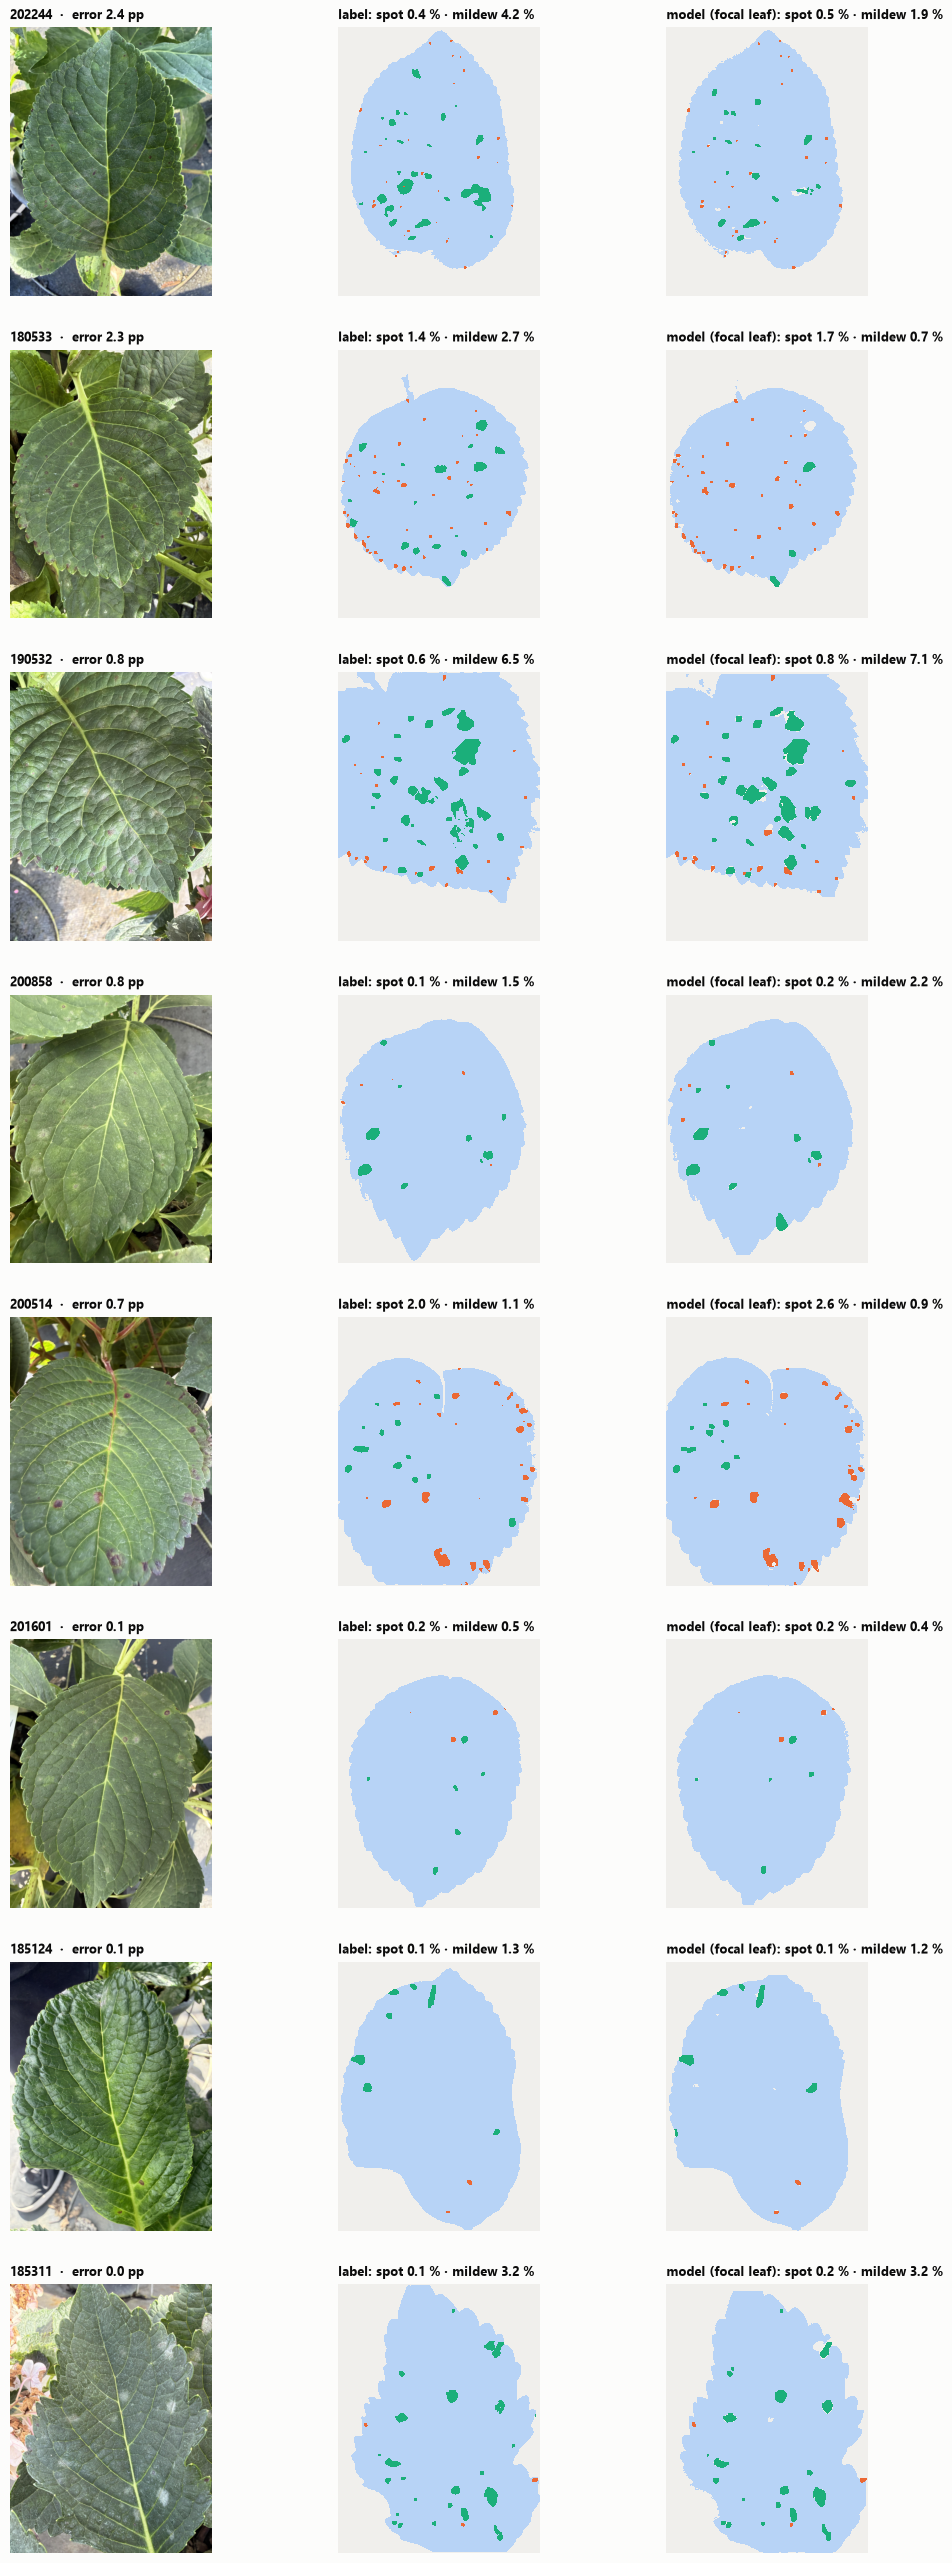

In [14]:
rs = by_mode["app"]
err = {f: abs(rs[f]["region_powdery_mildew"] - rs[f]["gt_powdery_mildew"]) + abs(rs[f]["region_leaf_spot"] - rs[f]["gt_leaf_spot"])
       for f in FILES}
order = sorted(FILES, key=lambda f: -err[f])
show = order[:5] + order[-3:]  # 5 largest coverage errors, 3 best
fig, axes = plt.subplots(len(show), 3, figsize=(12, 4.1 * len(show)))
for axr, f in zip(axes, show):
    img = next(im for im in images if im["file_name"] == f)
    im = app_image(coco_dir / "test" / f)
    g = gt_at(img, im.size)
    gt_map = paint_class_map(sum(g.values(), []), sum(([c] * len(g[c]) for c in g), []), im.size[::-1])
    pred_map, region = keep_maps[f]
    axr[0].imshow(im); axr[0].set_title(f"{f[9:15]}  ·  error {err[f]:.1f} pp", fontsize=9)
    axr[1].imshow(gt_map, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[1].set_title(f"label: spot {rs[f]['gt_leaf_spot']:.1f} % · mildew {rs[f]['gt_powdery_mildew']:.1f} %", fontsize=9)
    shown = np.where(region, pred_map, 0)
    axr[2].imshow(shown, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[2].set_title(f"model (focal leaf): spot {rs[f]['region_leaf_spot']:.1f} % · mildew {rs[f]['region_powdery_mildew']:.1f} %", fontsize=9)
    for ax in axr:
        ax.axis("off")
fig.savefig(OUT / "examples.png", dpi=90); plt.show()

## Save

In [15]:
with open(OUT / "per_image.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0]))
    w.writeheader(); w.writerows(rows)
json.dump({"project": PROJECT, "version": VERSION, "checkpoint": str(CHECKPOINT.relative_to(ROOT)), "thresholds": THRESH,
           "photos_scored": len(FILES), "photos_without_leaf_label": NO_LEAF, "metrics": RESULTS, "mask_ap": AP,
           "ultralytics_isolated": {"map50": float(val_iso.seg.map50), "map50_95": float(val_iso.seg.map)},
           "ultralytics_raw": {"map50": float(val_raw.seg.map50), "map50_95": float(val_raw.seg.map)}},
          open(OUT / "metrics.json", "w"), indent=1, default=float)
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['13_focal_test_report_executed.ipynb', 'coverage_scatter.png', 'examples.png', 'isolated.yaml', 'isolated_yolo', 'metrics.json', 'per_image.csv', 'pixel_confusion_app.png', 'pixel_metrics.png', 'raw.yaml', 'ultralytics_isolated', 'ultralytics_raw']


# From-scratch test set (`powdery-mildew-ds2-scratch-test`)

The same evaluation on photos labelled **from scratch, with no model pre-labels** (focal leaf only). Photos without a leaf label are left out, as above. Results go to their own folder.

In [16]:
PROJECT, VERSION = "powdery-mildew-ds2-scratch-test", 1
OUT = ROOT / "results" / f"focal_test_{PROJECT}-v{VERSION}"
OUT.mkdir(parents=True, exist_ok=True)
print("project:", PROJECT, "v", VERSION, "| results ->", OUT.relative_to(ROOT))

project: powdery-mildew-ds2-scratch-test v 1 | results -> results\focal_test_powdery-mildew-ds2-scratch-test-v1


In [17]:
coco_dir, yolo_yaml = ensure_dataset(ROOT, PROJECT, VERSION, os.environ["ROBOFLOW_API_KEY"], os.environ["ROBOFLOW_WORKSPACE"])
gt = COCO(str(coco_dir / "test" / "_annotations.coco.json"))
CAT = {c["id"]: c["name"] for c in gt.loadCats(gt.getCatIds())}
CAT_ID = {n: i for i, n in CAT.items() if n in CLASSES}
images = sorted(gt.loadImgs(gt.getImgIds()), key=lambda im: im["file_name"])

counts = collections.Counter(CAT[a["category_id"]] for a in gt.loadAnns(gt.getAnnIds()))
leaves_per_img = collections.Counter(a["image_id"] for a in gt.loadAnns(gt.getAnnIds(catIds=[CAT_ID["leaf"]])))
NO_LEAF = [im["file_name"] for im in images if leaves_per_img[im["id"]] == 0]
MULTI_LEAF = [im["file_name"] for im in images if leaves_per_img[im["id"]] > 1]
print(f"{len(images)} photos | sizes {dict(collections.Counter((im['width'], im['height']) for im in images))}")
print("instances:", {c: counts[c] for c in CLASSES[1:]})
print("photos with no leaf label (left out of the scores):", NO_LEAF or "none")
print("photos with >1 leaf label (treated as one focal leaf):", MULTI_LEAF or "none")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
8 photos | sizes {(3024, 4032): 8}
instances: {'leaf': 8, 'leaf_spot': 94, 'powdery_mildew': 118}
photos with no leaf label (left out of the scores): none
photos with >1 leaf label (treated as one focal leaf): none


leaf_spot       present on 8/8 leaves | median 0.42 % | max 0.5 % | severity bands {'mild': 8}
powdery_mildew  present on 8/8 leaves | median 1.90 % | max 5.7 % | severity bands {'mild': 7, 'moderate': 1}


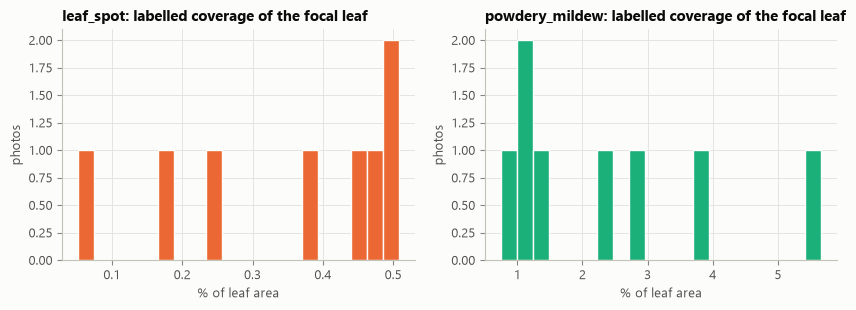

In [18]:
def app_image(path):
    # Same as backend/app/routes/scans.py load_image: EXIF orientation, long side capped at 1280.
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    im.thumbnail((APP_SIDE, APP_SIDE), Image.Resampling.LANCZOS)
    return im


def gt_at(img, size):
    # Labelled masks rasterised directly at the working size (polygons scaled, no full-res masks in memory).
    w, h = size
    sx, sy = w / img["width"], h / img["height"]
    out = {c: [] for c in CLASSES[1:]}
    for a in gt.loadAnns(gt.getAnnIds(imgIds=img["id"])):
        name = CAT[a["category_id"]]
        if name not in out:
            continue
        polys = [[v * (sx if k % 2 == 0 else sy) for k, v in enumerate(p)] for p in a["segmentation"] if len(p) >= 6]
        if polys:
            out[name].append(mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))).astype(bool))
    return out


def focal_leaf(g):
    # Focal leaf = all leaf shapes + the lesions on them, holes filled (lesions count as leaf area, as in the app).
    if not g["leaf"]:
        return None
    return fill_holes(np.logical_or.reduce(g["leaf"] + g["leaf_spot"] + g["powdery_mildew"]))


def dilate(mask, px):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * px + 1, 2 * px + 1))
    return cv2.dilate(mask.astype(np.uint8), k).astype(bool)


def sev(pct):
    return "none" if pct <= 0 else severity(pct)  # backend: 0 % -> "none"


# Ground-truth coverage of the focal leaf (what a perfect model would report).
gt_cov = {}
for img in images:
    im = app_image(coco_dir / "test" / img["file_name"])
    g = gt_at(img, im.size)
    leaf = focal_leaf(g)
    if leaf is not None:
        gt_cov[img["file_name"]] = {d: 100 * (np.logical_or.reduce(g[d] or [np.zeros_like(leaf)]) & leaf).sum() / leaf.sum()
                                    for d in DISEASES}
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, d in zip(axes, DISEASES):
    v = [c[d] for c in gt_cov.values()]
    ax.hist(v, bins=20, color=CLASS_COLOR[d], edgecolor=SURFACE)
    ax.set_title(f"{d}: labelled coverage of the focal leaf")
    ax.set_xlabel("% of leaf area"); ax.set_ylabel("photos")
    print(f"{d:<15} present on {sum(x > 0 for x in v)}/{len(v)} leaves | median {np.median(v):.2f} % | max {max(v):.1f} % | "
          f"severity bands {dict(collections.Counter(sev(x) for x in v))}")
plt.show()

### Run the model (three modes)

- **Predictions:** kept at the tuned per-class thresholds, as in the backend.
- **Scoring region:** each photo is scored only inside its labelled focal leaf (2-px edge, no margin), so neighbouring leaves are greyed out / ignored.
- **Instance level:** a predicted instance counts if at least half of it lies in that region. Predictions on other
  leaves are ignored.

In [19]:
model = YOLO(CHECKPOINT)


def predict(im, imgsz, out_size):
    r = model.predict(im, imgsz=imgsz, conf=min(THRESH.values()), iou=0.7, retina_masks=True, max_det=300, verbose=False)[0]
    if r.masks is None:
        return []
    preds = []
    for m, c, s in zip(r.masks.data.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
        name = r.names[int(c)]
        if s >= THRESH[name]:
            m = m.astype(bool)
            if m.shape[::-1] != out_size:  # train-style: back from the stretched square to the photo's shape
                m = cv2.resize(m.astype(np.uint8), out_size, interpolation=cv2.INTER_NEAREST).astype(bool)
            if m.any():
                preds.append((name, float(s), m))
    return preds


rows, conf_mats, dets, keep_maps = [], {m: {} for m in MODES}, {m: [] for m in MODES}, {}
gt_small = {"images": [], "annotations": [], "categories": [{"id": i, "name": n} for n, i in CAT_ID.items()]}
for k, img in enumerate(images, 1):
    name = img["file_name"]
    im = app_image(coco_dir / "test" / name)
    g = gt_at(img, im.size)
    leaf = focal_leaf(g)
    if leaf is None:
        continue
    h, w = leaf.shape
    region = dilate(leaf, max(2, int(REGION_MARGIN * max(h, w))))
    gt_map = paint_class_map(sum(g.values(), []), sum(([c] * len(g[c]) for c in g), []), (h, w))
    gt_small["images"].append({"id": img["id"], "file_name": name, "width": w, "height": h})
    for c, masks in g.items():
        for m in masks:
            rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
            rle["counts"] = rle["counts"].decode()
            gt_small["annotations"].append({"id": len(gt_small["annotations"]) + 1, "image_id": img["id"],
                                            "category_id": CAT_ID[c], "segmentation": rle, "iscrowd": 0,
                                            "area": float(m.sum()), "bbox": list(mask_utils.toBbox(rle))})
    inputs = {
        "app": (im, APP_IMGSZ),
        "train-style": (im.resize((TRAIN_SIZE, TRAIN_SIZE), Image.Resampling.BILINEAR), TRAIN_SIZE),
        "isolated": (Image.fromarray(np.where(region[..., None], np.asarray(im), np.array(GREY, np.uint8))), APP_IMGSZ),
    }
    for mode, (x, imgsz) in inputs.items():
        preds = predict(x, imgsz, (w, h))
        names = [p[0] for p in preds]
        masks = [p[2] for p in preds]
        pred_map = paint_class_map(masks, names, (h, w))
        conf_mats[mode][name] = confusion(gt_map[region], pred_map[region])
        if mode == "app":
            keep_maps[name] = (pred_map, region)
        # Coverage given the labelled leaf: predicted disease pixels inside it / its area.
        cov_region = {d: 100 * ((pred_map == CLASSES.index(d)) & leaf).sum() / leaf.sum() for d in DISEASES}
        # App rule: largest predicted leaf = primary, coverage computed exactly as the backend does.
        cov_app = coverage_primary_leaf(masks, names) or {d: 0.0 for d in DISEASES}
        pred_leaves = sorted((fill_holes(m) for n, _, m in preds if n == "leaf"), key=lambda m: -int(m.sum()))
        primary_iou = float((pred_leaves[0] & leaf).sum() / (pred_leaves[0] | leaf).sum()) if pred_leaves else 0.0
        rows.append({"file": name, "mode": mode, "primary_iou": primary_iou, "n_pred_leaves": len(pred_leaves),
                     **{f"gt_{d}": gt_cov[name][d] for d in DISEASES},
                     **{f"region_{d}": cov_region[d] for d in DISEASES},
                     **{f"app_{d}": cov_app[d] for d in DISEASES}})
        for n, s, m in preds:
            if (m & region).sum() >= 0.5 * m.sum():
                rle = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
                rle["counts"] = rle["counts"].decode()
                dets[mode].append({"image_id": img["id"], "category_id": CAT_ID[n], "segmentation": rle, "score": s})
    if k % 10 == 0 or k == len(images):
        print(f"{k}/{len(images)} photos", flush=True)
FILES = sorted(conf_mats["app"])
print(f"scored {len(FILES)} photos")

8/8 photos


scored 8 photos


### Metrics with 95 % bootstrap CIs

In [20]:
rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, len(FILES), len(FILES)) for _ in range(N_BOOT)]
by_mode = {m: {r["file"]: r for r in rows if r["mode"] == m} for m in MODES}


def pixel_scores(mats):
    c = sum(mats)
    tp = np.diag(c).astype(float)
    p, r = tp / np.maximum(c.sum(0), 1), tp / np.maximum(c.sum(1), 1)
    iou = iou_from_confusion(c)
    return {cls: {"precision": p[i], "recall": r[i], "f1": 2 * p[i] * r[i] / max(p[i] + r[i], 1e-9), "iou": iou[cls]}
            for i, cls in enumerate(CLASSES) if cls != "background"}


def coverage_scores(rs, key):
    out = {}
    for d in DISEASES:
        g = np.array([r[f"gt_{d}"] for r in rs]); p = np.array([r[f"{key}_{d}"] for r in rs])
        pos = g > 0
        tp, fp, fn = int(((p > 0) & pos).sum()), int(((p > 0) & ~pos).sum()), int(((p == 0) & pos).sum())
        out[d] = {"mae": float(np.abs(p - g).mean()), "mae_infected": float(np.abs(p - g)[pos].mean()) if pos.any() else np.nan,
                  "bias": float((p - g).mean()), "ccc": lins_ccc(g, p),
                  "severity_acc": float(np.mean([sev(a) == sev(b) for a, b in zip(g, p)])),
                  "presence_f1": 2 * tp / max(2 * tp + fp + fn, 1)}
    return out


def flat(d, prefix=""):
    out = {}
    for k, v in d.items():
        out.update(flat(v, f"{prefix}{k}.") if isinstance(v, dict) else {f"{prefix}{k}": v})
    return out


def scores(mode, idx):
    files = [FILES[i] for i in idx]
    rs = [by_mode[mode][f] for f in files]
    return flat({"pixel": pixel_scores([conf_mats[mode][f] for f in files]),
                 "coverage_given_leaf": coverage_scores(rs, "region"),
                 "coverage_app_rule": coverage_scores(rs, "app"),
                 "primary_leaf_correct": float(np.mean([r["primary_iou"] >= 0.5 for r in rs]))})


RESULTS = {}
for mode in MODES:
    point = scores(mode, np.arange(len(FILES)))
    boots = [scores(mode, b) for b in BOOT]
    RESULTS[mode] = {k: {"value": v, "ci95": [float(np.nanpercentile([b[k] for b in boots], 2.5)),
                                               float(np.nanpercentile([b[k] for b in boots], 97.5))]}
                     for k, v in point.items()}
print("bootstrap done")

bootstrap done


In [21]:
def fmt(mode, key, pct=False, digits=2):
    v = RESULTS[mode][key]
    f = (lambda x: f"{100 * x:.0f}%") if pct else (lambda x: f"{x:.{digits}f}")
    return f"{f(v['value'])} [{f(v['ci95'][0])}–{f(v['ci95'][1])}]"


table = [("Pixel IoU · leaf", "pixel.leaf.iou", False), ("Pixel IoU · leaf spot", "pixel.leaf_spot.iou", False),
         ("Pixel IoU · mildew", "pixel.powdery_mildew.iou", False),
         ("Pixel F1 · leaf spot", "pixel.leaf_spot.f1", False), ("Pixel F1 · mildew", "pixel.powdery_mildew.f1", False),
         ("Spot coverage MAE (pp)", "coverage_given_leaf.leaf_spot.mae", False),
         ("Mildew coverage MAE (pp)", "coverage_given_leaf.powdery_mildew.mae", False),
         ("Spot coverage bias (pp)", "coverage_given_leaf.leaf_spot.bias", False),
         ("Mildew coverage bias (pp)", "coverage_given_leaf.powdery_mildew.bias", False),
         ("Spot CCC", "coverage_given_leaf.leaf_spot.ccc", False), ("Mildew CCC", "coverage_given_leaf.powdery_mildew.ccc", False),
         ("Spot severity band correct", "coverage_given_leaf.leaf_spot.severity_acc", True),
         ("Mildew severity band correct", "coverage_given_leaf.powdery_mildew.severity_acc", True),
         ("App: mildew MAE (pp)", "coverage_app_rule.powdery_mildew.mae", False),
         ("App: spot MAE (pp)", "coverage_app_rule.leaf_spot.mae", False),
         ("App picks the focal leaf", "primary_leaf_correct", True)]
print(f"{'metric':<30}" + "".join(f"{m:>26}" for m in MODES))
for label, key, pct in table:
    print(f"{label:<30}" + "".join(f"{fmt(m, key, pct):>26}" for m in MODES))
print("\npp = percentage points of leaf area. 'given leaf' = coverage inside the labelled leaf; 'App' = backend rule "
      "(largest predicted leaf). [95 % CI]")

metric                                               app               train-style                  isolated
Pixel IoU · leaf                        0.97 [0.96–0.98]          0.95 [0.94–0.96]          0.98 [0.97–0.98]
Pixel IoU · leaf spot                   0.54 [0.47–0.60]          0.53 [0.45–0.59]          0.56 [0.49–0.61]
Pixel IoU · mildew                      0.62 [0.54–0.68]          0.61 [0.54–0.67]          0.63 [0.55–0.69]
Pixel F1 · leaf spot                    0.70 [0.64–0.75]          0.69 [0.62–0.74]          0.72 [0.66–0.76]
Pixel F1 · mildew                       0.77 [0.70–0.81]          0.76 [0.70–0.80]          0.77 [0.71–0.82]
Spot coverage MAE (pp)                  0.21 [0.13–0.30]          0.17 [0.12–0.23]          0.20 [0.12–0.28]
Mildew coverage MAE (pp)                0.60 [0.42–0.78]          0.64 [0.41–0.84]          0.62 [0.39–0.84]
Spot coverage bias (pp)                 0.21 [0.13–0.30]          0.17 [0.12–0.23]          0.20 [0.12–0.28]
Mildew coverage bia

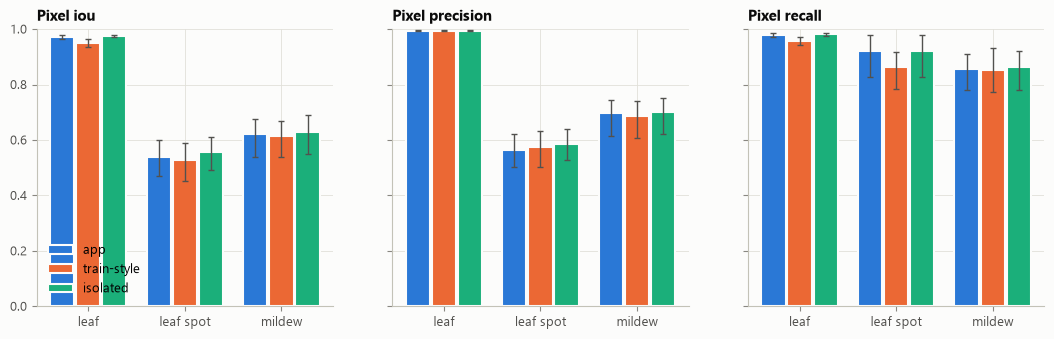

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, metric in zip(axes, ("iou", "precision", "recall")):
    x = np.arange(3)
    for j, mode in enumerate(MODES):
        vals = [RESULTS[mode][f"pixel.{c}.{metric}"] for c in ("leaf", "leaf_spot", "powdery_mildew")]
        y = np.array([v["value"] for v in vals]); lo = y - [v["ci95"][0] for v in vals]; hi = [v["ci95"][1] for v in vals] - y
        ax.bar(x + (j - 1) * 0.27, y, 0.25, yerr=[lo, hi], color=MODE_COLOR[mode], edgecolor=SURFACE, linewidth=1.5,
               error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2}, label=mode)
    ax.set_xticks(x, ["leaf", "leaf spot", "mildew"]); ax.set_ylim(0, 1); ax.set_title(f"Pixel {metric}")
axes[0].legend(loc="lower left")
fig.savefig(OUT / "pixel_metrics.png"); plt.show()

### Pixel confusion inside the focal leaf (app mode, rows = label, normalised)

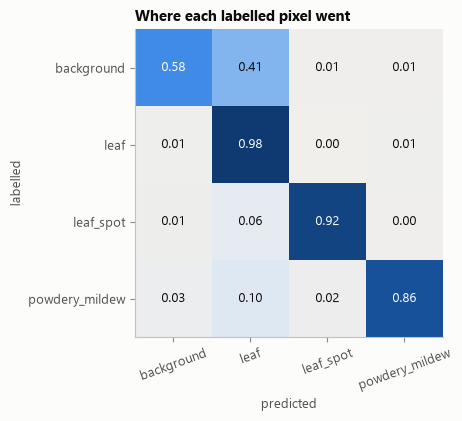

In [23]:
c = sum(conf_mats["app"][f] for f in FILES).astype(float)
c = c[1:, 1:] if c[0].sum() == 0 else c  # background is only the margin around the leaf; keep it if present
labels = CLASSES[1:] if c.shape[0] == 3 else CLASSES
cn = c / np.maximum(c.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cn, cmap=BLUES, vmin=0, vmax=1); ax.grid(False)
for i in range(cn.shape[0]):
    for j in range(cn.shape[1]):
        ax.text(j, i, f"{cn[i, j]:.2f}", ha="center", va="center", color="white" if cn[i, j] > 0.55 else INK, fontsize=9)
ax.set_xticks(range(len(labels)), labels, rotation=20); ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("predicted"); ax.set_ylabel("labelled"); ax.set_title("Where each labelled pixel went")
fig.savefig(OUT / "pixel_confusion_app.png"); plt.show()

### Coverage: labelled vs predicted (app mode, given the labelled leaf)

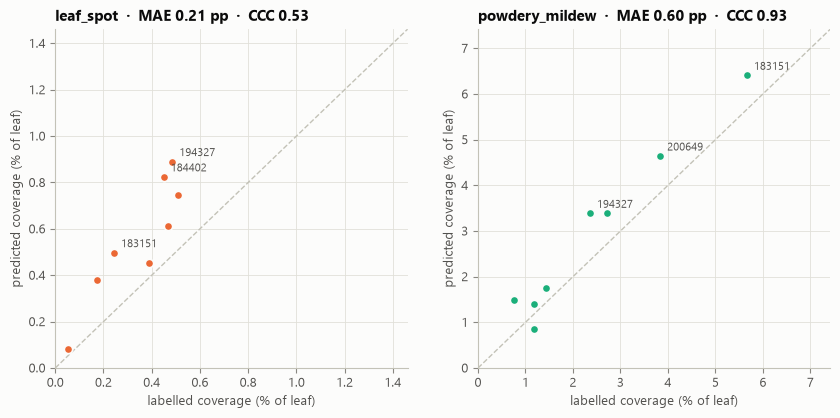

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, d in zip(axes, DISEASES):
    rs = list(by_mode["app"].values())
    g = np.array([r[f"gt_{d}"] for r in rs]); p = np.array([r[f"region_{d}"] for r in rs])
    top = max(g.max(), p.max()) * 1.08 + 0.5
    ax.plot([0, top], [0, top], color=AXIS, linewidth=1, linestyle="--", zorder=1)
    ax.scatter(g, p, s=36, color=CLASS_COLOR[d], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.set_xlim(0, top); ax.set_ylim(0, top)
    ax.set_xlabel("labelled coverage (% of leaf)"); ax.set_ylabel("predicted coverage (% of leaf)")
    r = RESULTS["app"]
    ax.set_title(f"{d}  ·  MAE {r[f'coverage_given_leaf.{d}.mae']['value']:.2f} pp  ·  "
                 f"CCC {r[f'coverage_given_leaf.{d}.ccc']['value']:.2f}")
    worst = np.argsort(-np.abs(p - g))[:3]
    for i in worst:
        ax.annotate(rs[i]["file"][9:15], (g[i], p[i]), textcoords="offset points", xytext=(5, 4), fontsize=8, color=INK2)
fig.savefig(OUT / "coverage_scatter.png"); plt.show()

### Instance level: mask AP (COCO), predictions on the focal leaf only

In [25]:
gt_coco = COCO(); gt_coco.dataset = gt_small; gt_coco.createIndex()
AP = {}
for mode in MODES:
    dt = gt_coco.loadRes(dets[mode]) if dets[mode] else None
    if dt is None:
        continue
    ev = COCOeval(gt_coco, dt, "segm"); ev.params.maxDets = [10, 100, 300]
    ev.evaluate(); ev.accumulate()
    prec = ev.eval["precision"]  # [IoU thr, recall, class, area, maxDets]
    AP[mode] = {}
    for k, cid in enumerate(ev.params.catIds):
        p = prec[:, :, k, 0, -1]
        valid = lambda a: float(a[a > -1].mean()) if (a > -1).any() else float("nan")  # noqa: E731
        AP[mode][next(n for n, i in CAT_ID.items() if i == cid)] = {"ap50": valid(p[0]), "ap50_95": valid(p)}
print(f"{'class':<16}" + "".join(f"{m + ' AP50':>18}{m + ' AP50-95':>20}" for m in AP))
for c in CLASSES[1:]:
    print(f"{c:<16}" + "".join(f"{AP[m][c]['ap50']:>18.3f}{AP[m][c]['ap50_95']:>20.3f}" for m in AP))

creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.02s).
Accumulating evaluation results...
DONE (t=0.01s).
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.02s).
Accumulating evaluation results...
DONE (t=0.00s).
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.02s).
Accumulating evaluation results...
DONE (t=0.01s).
class                     app AP50         app AP50-95  train-style AP50 train-style AP50-95     isolated AP50    isolated AP50-95
leaf                         1.000               0.939             1.000               0.899             1.000               0.956
leaf_spot                    0.747               0.351             0.

### Ultralytics `val`

The isolated-leaf copies are written as a YOLO dataset: the labels are unchanged, and everything outside the focal leaf
is grey. This makes Ultralytics' own metrics and plots fair. For contrast, the same run on the **raw photos**: there,
every correct prediction on an unlabelled leaf counts as a false positive.

In [26]:
src = Path(yolo_yaml).parent / "test"
iso = OUT / "isolated_yolo"
shutil.rmtree(iso, ignore_errors=True)
(iso / "images").mkdir(parents=True); (iso / "labels").mkdir()
for img in gt_small["images"]:
    name = img["file_name"]
    im = app_image(coco_dir / "test" / name)
    region = dilate(focal_leaf(gt_at(gt.imgs[img["id"]], im.size)), max(2, int(REGION_MARGIN * max(im.size))))
    Image.fromarray(np.where(region[..., None], np.asarray(im), np.array(GREY, np.uint8))).save(iso / "images" / name, quality=95)
    shutil.copy(src / "labels" / (Path(name).stem + ".txt"), iso / "labels")
names = yaml.safe_load(open(yolo_yaml))["names"]
assert list(names) == list(YOLO(CHECKPOINT).names.values()), f"class order differs: {names}"
iso_yaml = OUT / "isolated.yaml"
yaml.safe_dump({"path": str(iso), "train": "images", "val": "images", "names": names}, open(iso_yaml, "w"))

val_iso = model.val(data=str(iso_yaml), imgsz=APP_IMGSZ, batch=4, conf=0.001, iou=0.7, workers=0, plots=True,
                    project=str(OUT), name="ultralytics_isolated", exist_ok=True, verbose=True)
raw_yaml = OUT / "raw.yaml"
yaml.safe_dump({"path": str(src.parent), "train": "test/images", "val": "test/images", "names": names}, open(raw_yaml, "w"))
val_raw = model.val(data=str(raw_yaml), imgsz=APP_IMGSZ, batch=4, conf=0.001, iou=0.7, workers=0, plots=False,
                    project=str(OUT), name="ultralytics_raw", exist_ok=True, verbose=False)
print(f"\nmask mAP50 · isolated leaf {val_iso.seg.map50:.3f} vs raw photos {val_raw.seg.map50:.3f} "
      f"(unlabelled leaves count as false positives in the raw run)")
for i, c in enumerate(val_iso.seg.ap_class_index):
    j = list(val_raw.seg.ap_class_index).index(c)
    print(f"  {names[c]:<15} isolated mAP50 {val_iso.seg.ap50[i]:.3f}  mAP50-95 {val_iso.seg.ap[i]:.3f}   |  raw mAP50 {val_raw.seg.ap50[j]:.3f}")

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)


YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1039.9±422.0 MB/s, size: 435.6 KB)


val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_test_powdery-mildew-ds2-scratch-test-v1\isolated_yolo\labels... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 920.3it/s 0.0s

val: New cache created: C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_test_powdery-mildew-ds2-scratch-test-v1\isolated_yolo\labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 1.9it/s 0.2s<0.5s

... (12 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.0it/s 0.5s

                   all          8        220      0.505      0.776      0.529      0.345      0.511      0.737      0.496      0.288


Speed: 0.3ms preprocess, 17.7ms inference, 0.0ms loss, 1.9ms postprocess per image



mask mAP50 · isolated leaf 0.840 vs raw photos 0.496 (unlabelled leaves count as false positives in the raw run)
  leaf            isolated mAP50 0.995  mAP50-95 0.995   |  raw mAP50 0.150
  leaf_spot       isolated mAP50 0.762  mAP50-95 0.349   |  raw mAP50 0.667
  powdery_mildew  isolated mAP50 0.764  mAP50-95 0.433   |  raw mAP50 0.672


MaskPR_curve.png


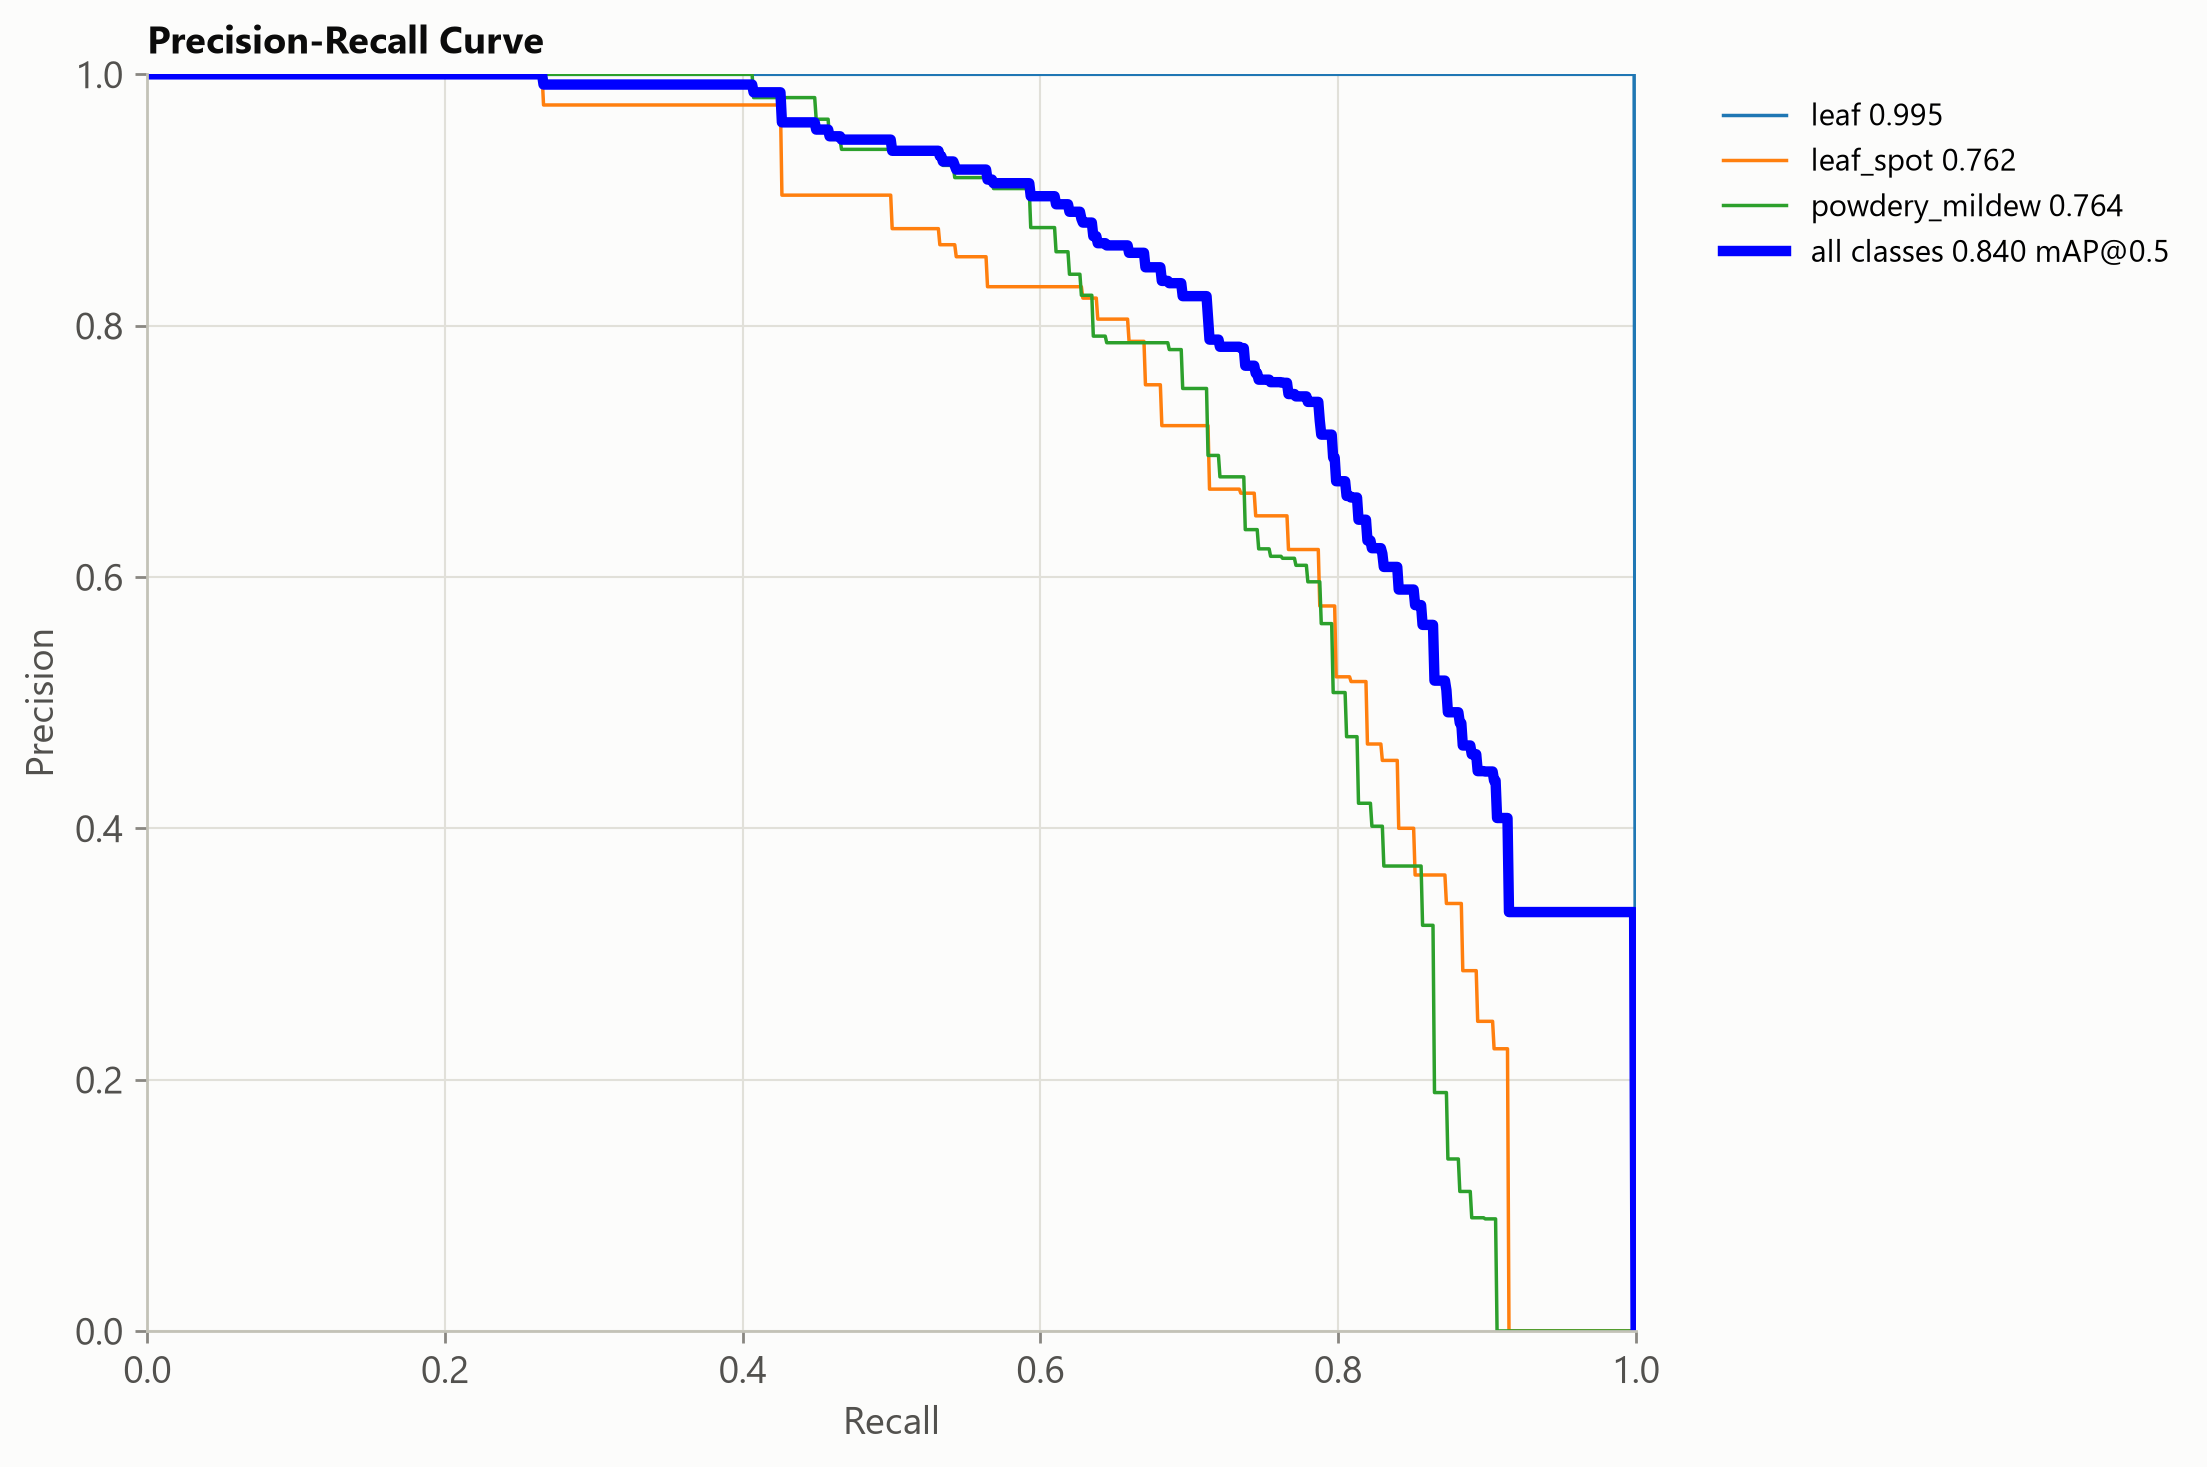

confusion_matrix_normalized.png


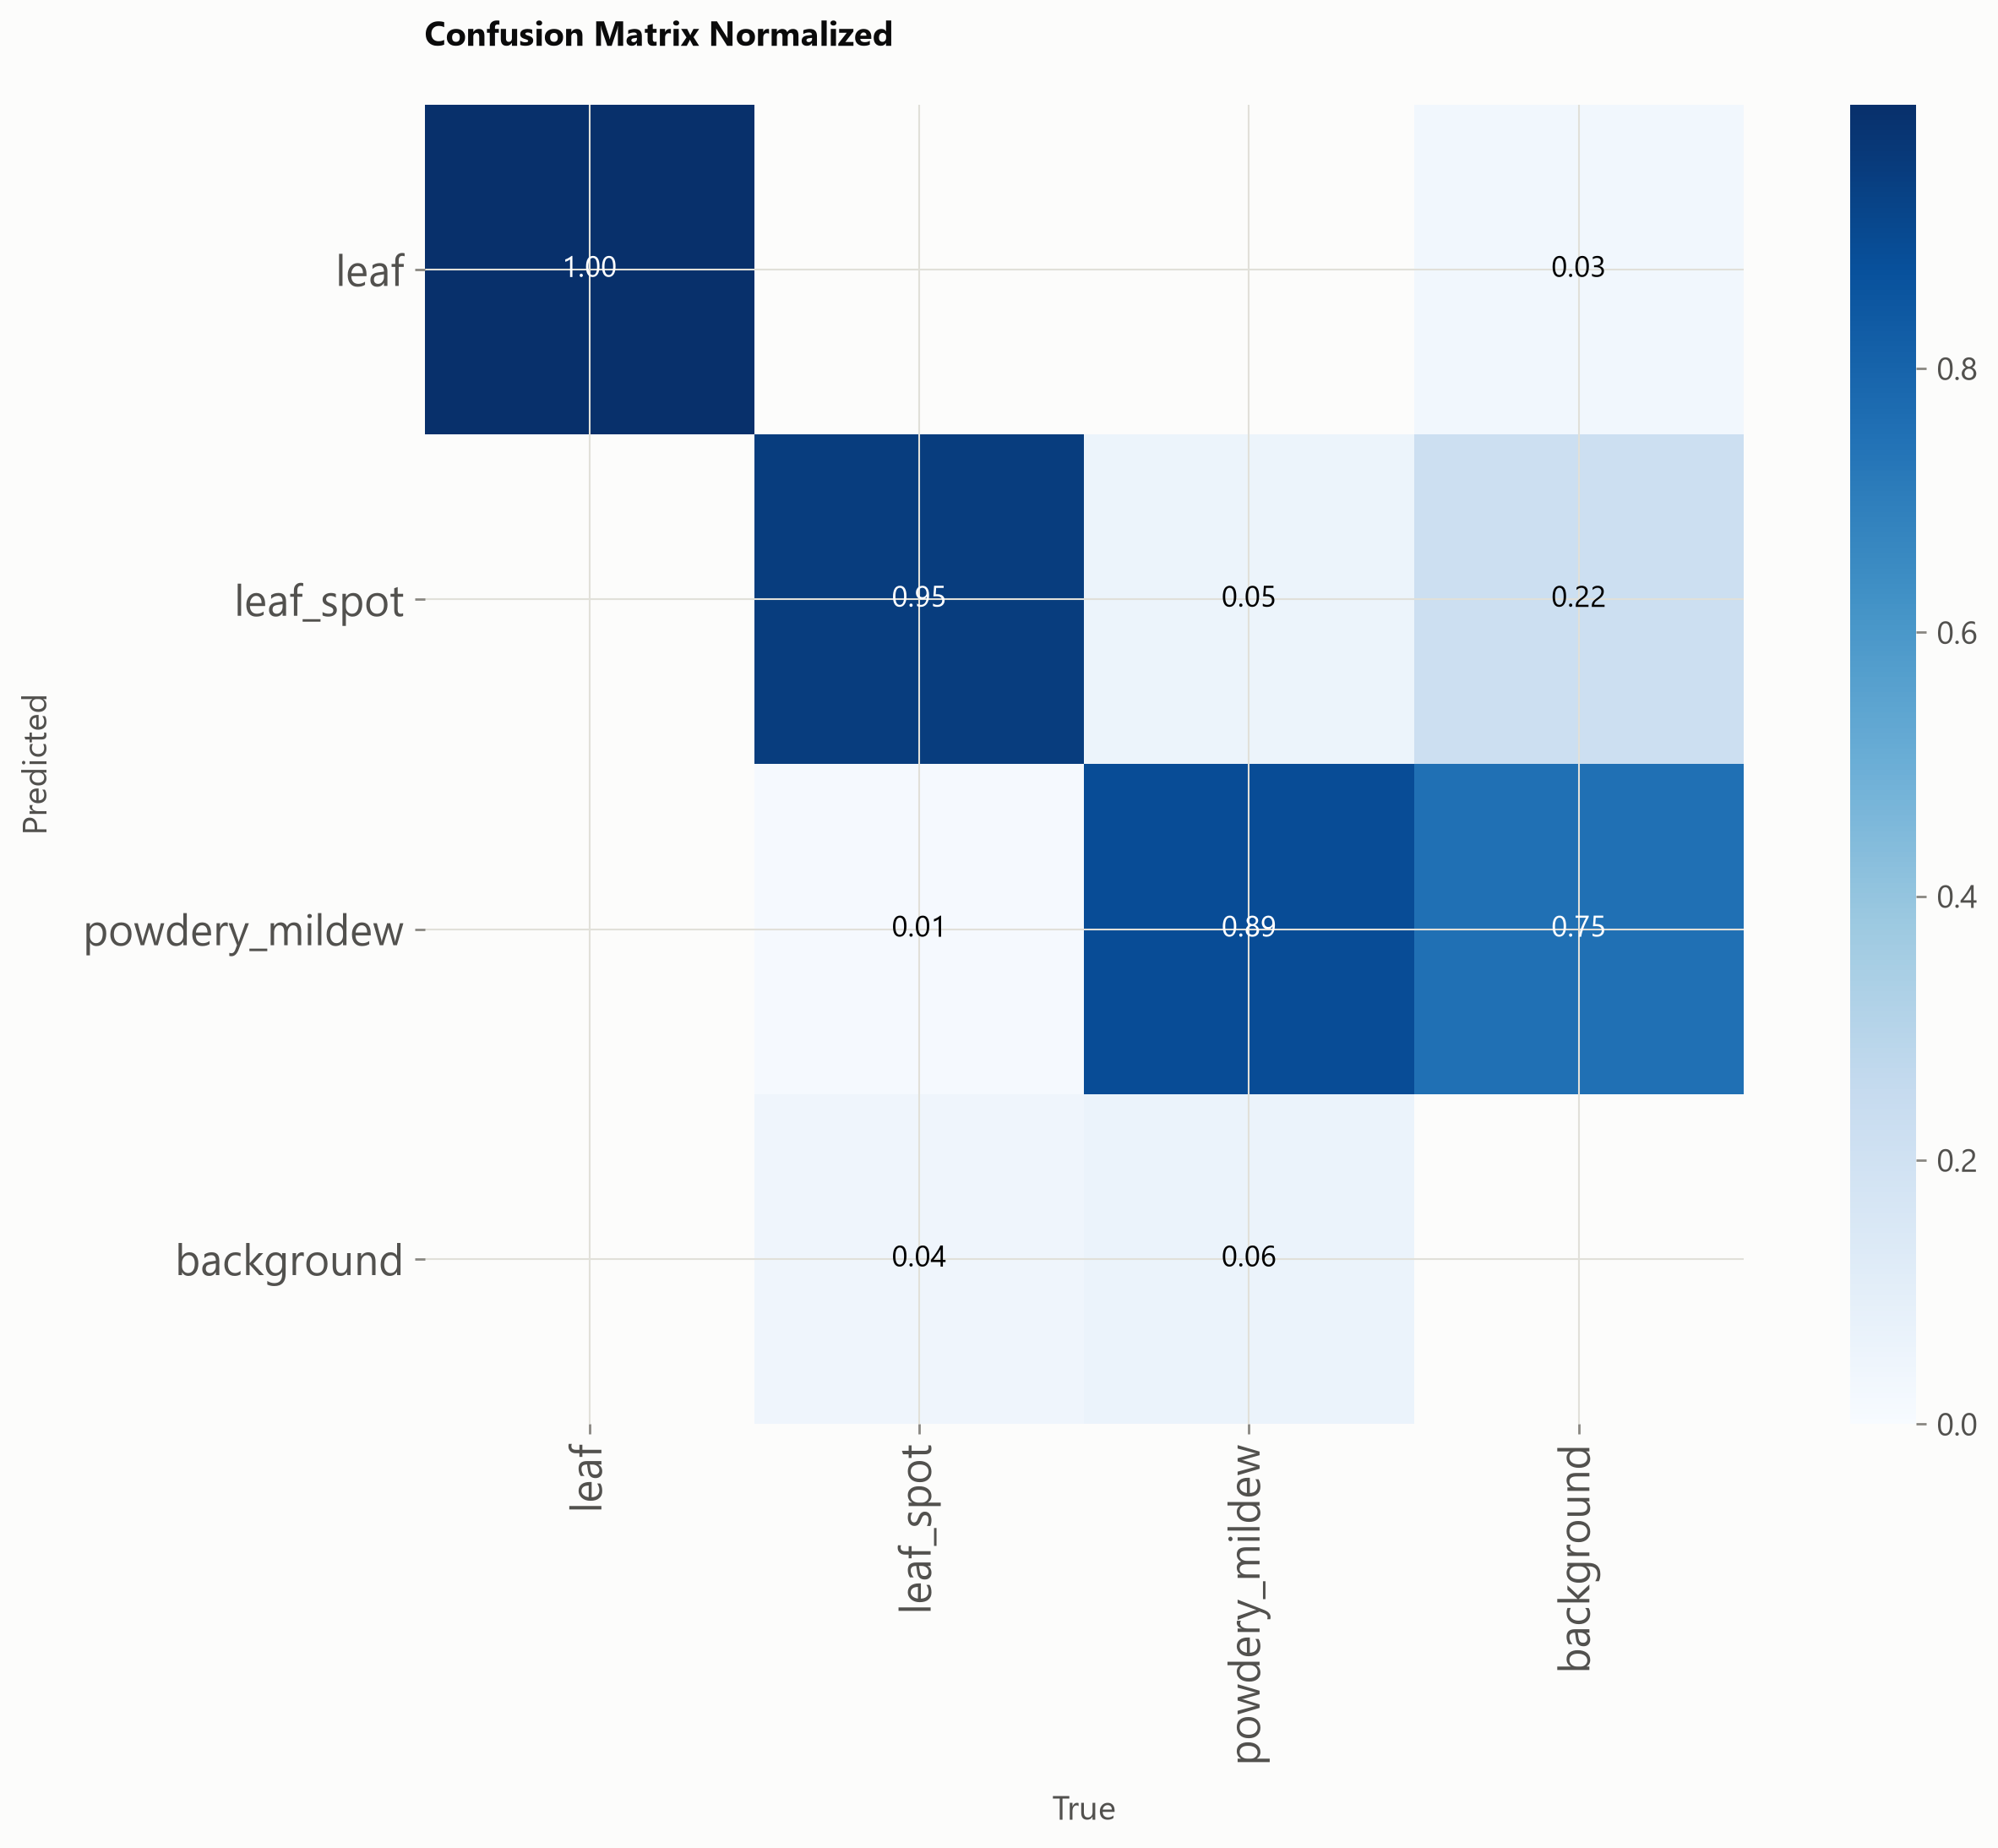

val_batch0_pred.jpg


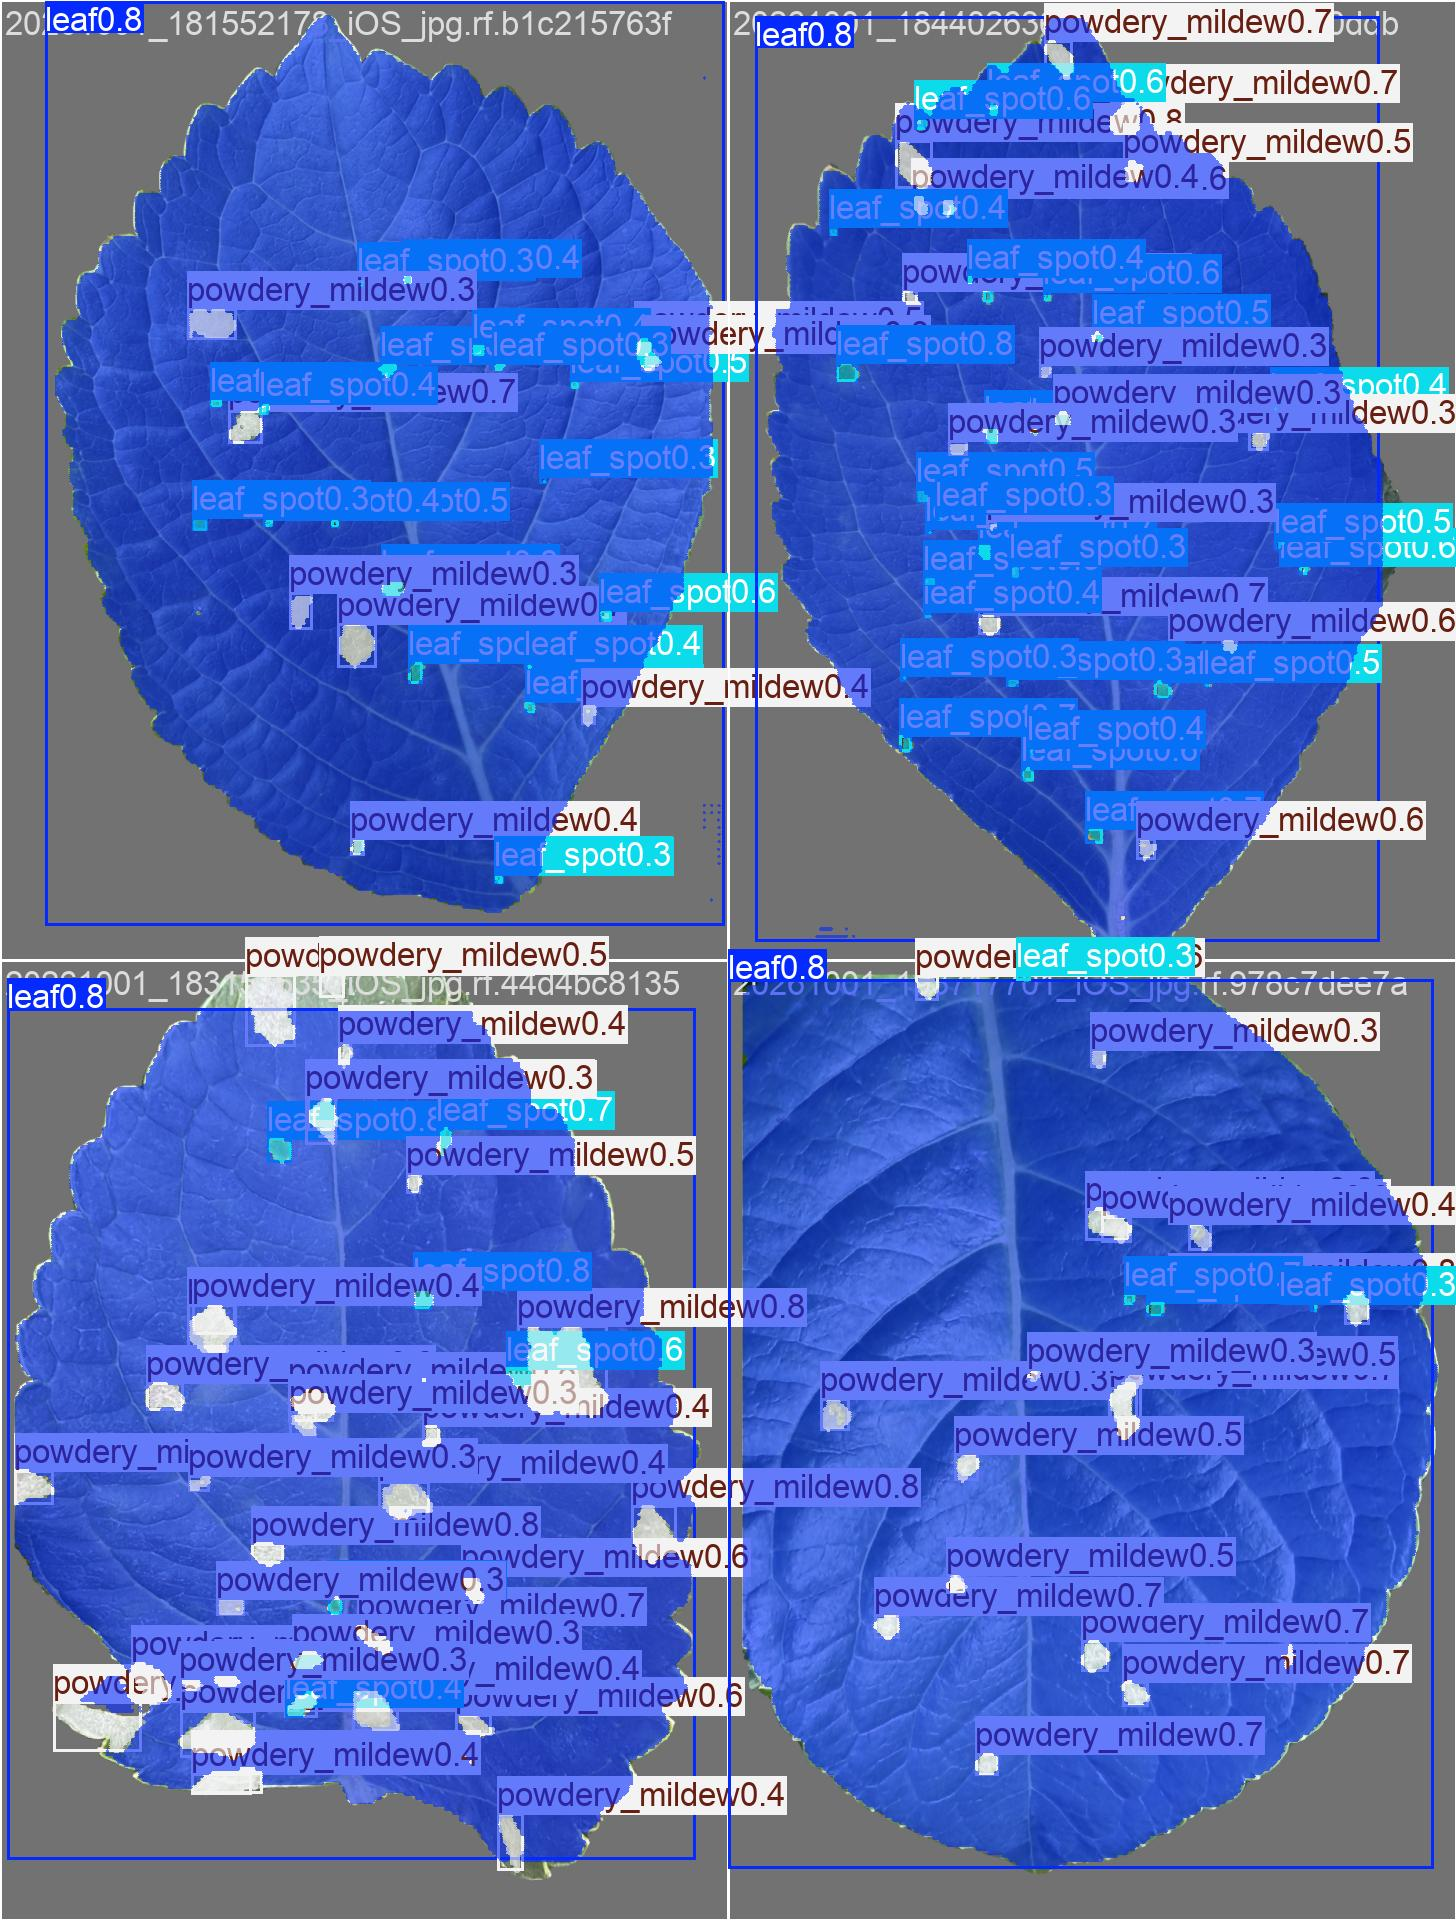

In [27]:
plots = OUT / "ultralytics_isolated"
for f in ("MaskPR_curve.png", "confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    p = plots / f
    if p.exists():
        print(f); display(IPImage(filename=str(p), width=760))

### Pictures: where the model is right and wrong (app mode)

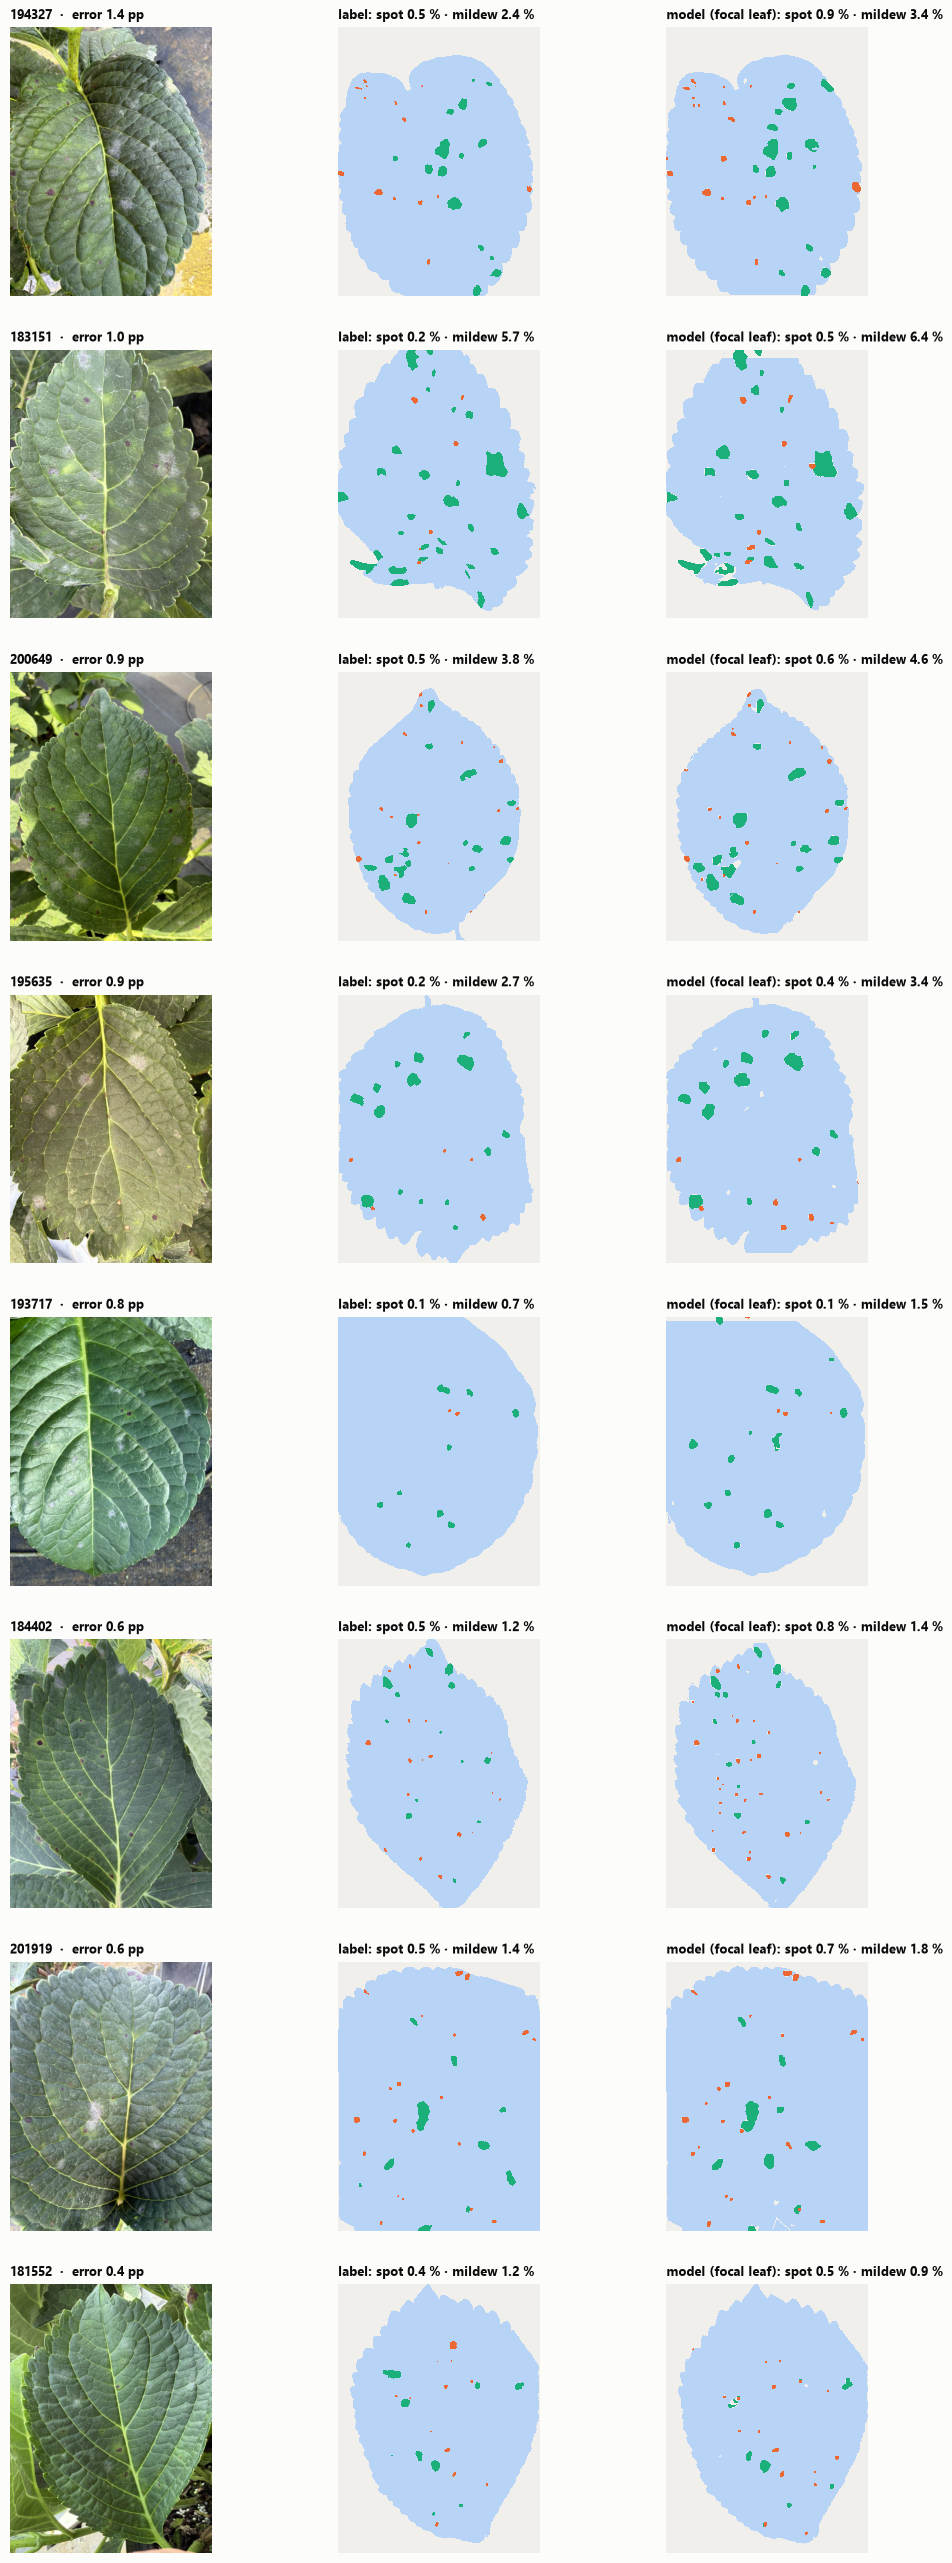

In [28]:
rs = by_mode["app"]
err = {f: abs(rs[f]["region_powdery_mildew"] - rs[f]["gt_powdery_mildew"]) + abs(rs[f]["region_leaf_spot"] - rs[f]["gt_leaf_spot"])
       for f in FILES}
order = sorted(FILES, key=lambda f: -err[f])
show = order[:5] + order[-3:]  # 5 largest coverage errors, 3 best
fig, axes = plt.subplots(len(show), 3, figsize=(12, 4.1 * len(show)))
for axr, f in zip(axes, show):
    img = next(im for im in images if im["file_name"] == f)
    im = app_image(coco_dir / "test" / f)
    g = gt_at(img, im.size)
    gt_map = paint_class_map(sum(g.values(), []), sum(([c] * len(g[c]) for c in g), []), im.size[::-1])
    pred_map, region = keep_maps[f]
    axr[0].imshow(im); axr[0].set_title(f"{f[9:15]}  ·  error {err[f]:.1f} pp", fontsize=9)
    axr[1].imshow(gt_map, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[1].set_title(f"label: spot {rs[f]['gt_leaf_spot']:.1f} % · mildew {rs[f]['gt_powdery_mildew']:.1f} %", fontsize=9)
    shown = np.where(region, pred_map, 0)
    axr[2].imshow(shown, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[2].set_title(f"model (focal leaf): spot {rs[f]['region_leaf_spot']:.1f} % · mildew {rs[f]['region_powdery_mildew']:.1f} %", fontsize=9)
    for ax in axr:
        ax.axis("off")
fig.savefig(OUT / "examples.png", dpi=90); plt.show()

### Save

In [29]:
with open(OUT / "per_image.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0]))
    w.writeheader(); w.writerows(rows)
json.dump({"project": PROJECT, "version": VERSION, "checkpoint": str(CHECKPOINT.relative_to(ROOT)), "thresholds": THRESH,
           "photos_scored": len(FILES), "photos_without_leaf_label": NO_LEAF, "metrics": RESULTS, "mask_ap": AP,
           "ultralytics_isolated": {"map50": float(val_iso.seg.map50), "map50_95": float(val_iso.seg.map)},
           "ultralytics_raw": {"map50": float(val_raw.seg.map50), "map50_95": float(val_raw.seg.map)}},
          open(OUT / "metrics.json", "w"), indent=1, default=float)
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['coverage_scatter.png', 'examples.png', 'isolated.yaml', 'isolated_yolo', 'metrics.json', 'per_image.csv', 'pixel_confusion_app.png', 'pixel_metrics.png', 'raw.yaml', 'ultralytics_isolated', 'ultralytics_raw']
